# ЛАБОРАТОРНА РОБОТА № 4

## Візуальний аналіз даних та часові ряди — аналіз у двох середовищах

**Курс:** СК26 «Інтелектуальний аналіз та візуалізація даних»
**Кафедра систем штучного інтелекту, Національний університет «Львівська політехніка»**
**Оцінювання:** 4 бали

---

## Визначення варіанта

Заповніть три поля в клітинці нижче й виконайте обидві службові клітинки —
номер варіанта, ринок і товар визначаться автоматично.

In [1]:
# ── Заповніть три поля ──────────────────────────────────────────
SURNAME_NAME = 'Щербан Ярина'  
GROUP        = 'ШІ-32'     
NUMBER       = 18     

assert SURNAME_NAME.strip(), 'Впишіть прізвище та ім\'я'
assert GROUP.strip(),        'Впишіть групу'
assert isinstance(NUMBER, int) and 1 <= NUMBER <= 30, 'Номер має бути цілим від 1 до 30'
print('Дані прийнято:', SURNAME_NAME, '|', GROUP, '| номер', NUMBER)

Дані прийнято: Щербан Ярина | ШІ-32 | номер 18


In [2]:
# ── Службова клітинка: визначення варіанта. Змінювати не потрібно ──
import json

VARIANTS = json.load(open('lr4_variants_student.json', encoding='utf-8'))
V = VARIANTS[NUMBER - 1]

MARKET, GOOD, GOOD_UA = V['ринок'], V['товар'], V['товар_укр']

print('=' * 72)
print(f'ВАРІАНТ {V["варіант"]}   ·   {SURNAME_NAME}   ·   {GROUP}')
print('=' * 72)
print()
print(f'   Ринок:  {MARKET}')
print(f'   Товар:  {GOOD_UA}   (у наборі даних: {GOOD})')
print()
print('Далі в роботі користуйтеся змінними MARKET і GOOD —')
print('тоді весь код автоматично працюватиме саме з вашим рядом.')
print()
print('Період: 03.2014 – 12.2017 · очікувана довжина ряду: 46 місяців')
print('Фолдів ретроспективної перевірки: 7 · горизонт: 3 місяці · ARIMA(1, 1, 1)')

ВАРІАНТ 18   ·   Щербан Ярина   ·   ШІ-32

   Ринок:  Khmelnytskyi
   Товар:  курятина   (у наборі даних: Meat (chicken, whole) - Retail)

Далі в роботі користуйтеся змінними MARKET і GOOD —
тоді весь код автоматично працюватиме саме з вашим рядом.

Період: 03.2014 – 12.2017 · очікувана довжина ряду: 46 місяців
Фолдів ретроспективної перевірки: 7 · горизонт: 3 місяці · ARIMA(1, 1, 1)


> ⚠️ Якщо ці дві клітинки не виконано, усі подальші завдання не мають сенсу:
> перевіряти роботу будуть **за вашим варіантом**, а не за тим рядом, який ви оберете самі.

| | |
|---|---|
| **Дата здачі** | |
| **Підпис** | |

---
## Мета роботи

Виконати повний цикл аналізу одного часового ряду **у двох середовищах** — у Python та в Orange —
і пояснити, чому однаково названі метрики в них дають різні числа.

## Вихідні дані

| Файл | Зміст |
|---|---|
| `ціни_україна_2014_2017.csv` | Роздрібні ціни на 25 товарів по 28 ринках України, щомісяця, 03.2014 – 12.2017 |
| `lr4_variants_student.json` | Розподіл варіантів (зчитується автоматично) |
| `ЛР4_помилковий_аналіз.ipynb` | Звіт колеги, який треба відрецензувати (завдання 8) |

Це той самий набір, з яким ми працювали на лекції 4. **Національне середнє в завданнях не використовується** —
ваш ряд це конкретний обласний ринок.

## Що здавати

1. **`ЛР4_Прізвище_Варіант.ipynb`** — цей зошит із вашим кодом, графіками та письмовими висновками.
2. **`ряд_для_orange.csv`** — експортований ряд (завдання 9).
3. **`потік_orange.ows`** — збережений потік Orange.
4. **Знімки екрана** з Orange для завдань 10–13 — вставте їх у зошит або додайте окремими файлами.

## Правила

* **Код пишете самостійно** — у цьому зошиті навмисно немає заготовок.
* **Користуватися штучним інтелектом дозволено**, але ви зобов'язані заповнити декларацію в кінці зошита.
* **Кожне число має супроводжуватися висновком словами.** Робота, у якій є графіки й таблиці,
  але немає письмових відповідей на поставлені питання, оцінюється як невиконана.
* Усі обчислення мають бути **відтворюваними**: зошит має виконуватися від початку до кінця
  командою *Restart & Run All* без помилок.

---
# ЧАСТИНА 1. Аналіз засобами Python

*Виконується аудиторно.*

## Завдання 1. Підготовка ряду

Витягніть із набору ряд свого варіанта — скористайтеся змінними `MARKET` і `GOOD`,
які визначилися у службовій клітинці, — і приведіть його до **повної місячної сітки**
з березня 2014 по грудень 2017.

**У звіті наведіть:**
1. скільки місяців у сітці та скільки з них мають вимір;
2. у якому саме місяці пропуск;
3. **чому** цей пропуск виник — і чи він у вашому ряді один.

> 💡 **Підказка.** Пропуск є в усіх без винятку рядах набору. Якщо ви знайшли більше одного — перевірте, чи правильно побудована сітка.

Ряд: Khmelnytskyi · Meat (chicken, whole) - Retail  (одиниця: KG, валюта: UAH)
Рядків у наборі для цього ряду: 45

Місяців у сітці: 46;  з виміром: 45;  без виміру: 1
Пропуск: ['2017-08']

Місяці сітки, яких немає в ЖОДНОМУ ряді всього набору: ['2017-08']

Ринків, які мають рівно 45 вимірів: 24 із 28. Решта:
ринок
Crimea            1
m. Sevastopol     2
Luhanska         40
Donetska         42


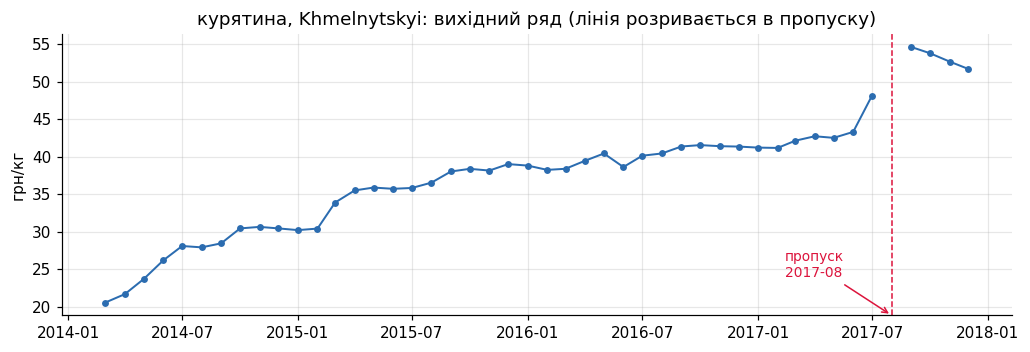

In [3]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams.update({
    'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.3,
    'axes.spines.top': False, 'axes.spines.right': False, 'font.size': 10,
})
RNG_SEED = 42
raw = pd.read_csv('ціни_україна_2014_2017.csv', encoding='utf-8')
raw['date'] = pd.to_datetime(dict(year=raw['рік'], month=raw['місяць'], day=1))

sub = raw[(raw['ринок'] == MARKET) & (raw['товар'] == GOOD)]
assert sub['date'].is_unique, 'у ряді є дублікати дат'
print(f'Ряд: {MARKET} · {GOOD}  (одиниця: {sub["одиниця"].iloc[0]}, валюта: {sub["валюта"].iloc[0]})')
print(f'Рядків у наборі для цього ряду: {len(sub)}')

GRID = pd.date_range('2014-03-01', '2017-12-01', freq='MS')
s_raw = sub.set_index('date')['ціна'].reindex(GRID).rename('price')
s_raw.index.name = 'date'

n_grid, n_obs = len(GRID), int(s_raw.notna().sum())
gaps = list(s_raw.index[s_raw.isna()])
print(f'\nМісяців у сітці: {n_grid};  з виміром: {n_obs};  без виміру: {n_grid - n_obs}')
print('Пропуск:', [d.strftime('%Y-%m') for d in gaps])
assert n_grid == 46 and len(gaps) == 1

months_in_data = set(raw['date'])
global_gaps = [d.strftime('%Y-%m') for d in GRID if d not in months_in_data]
print('\nМісяці сітки, яких немає в ЖОДНОМУ ряді всього набору:', global_gaps)

cnt = raw[raw['товар'] == GOOD].groupby('ринок')['date'].nunique().sort_values()
print(f'\nРинків, які мають рівно 45 вимірів: {(cnt == 45).sum()} із {len(cnt)}. Решта:')
print(cnt[cnt != 45].to_string())

fig, ax = plt.subplots(figsize=(9.5, 3.3))
ax.plot(s_raw.index, s_raw.values, '-o', ms=3.5, lw=1.3, color='#2b6cb0')
for g in gaps:
    ax.axvline(g, color='crimson', ls='--', lw=1)
    ax.annotate(f'пропуск\n{g:%Y-%m}', (g, ax.get_ylim()[0]), xytext=(-70, 25),
                textcoords='offset points', color='crimson', fontsize=9,
                arrowprops=dict(arrowstyle='->', color='crimson'))
ax.set_ylabel('грн/кг'); ax.set_title(f'{GOOD_UA}, {MARKET}: вихідний ряд (лінія розривається в пропуску)')
plt.tight_layout(); plt.show()

>**Висновок до завдання 1:**
>
>1. Повна місячна сітка з березня 2014 по грудень 2017 містить **46 місяців**; ряд «курятина, Хмельницький» має вимір у **45** із них, без виміру - **1**.
>2. Єдиний пропуск — **серпень 2017**.
>3. **Чому.** Це не особливість моєї області чи товару: місяця 2017-08 немає **в жодному ряді всього набору** (усі ринки й усі 25 товарів; перевірено за датами всього файлу). Отже, це системна прогалина самого джерела даних. Пропуск у моєму ряді **один**: сітку побудовано з кроком «початок місяця» (`freq='MS'`), як і самі дати в даних.
>
>Додатково: 24 із 28 ринків мають для цього товару рівно 45 вимірів. Інші чотири (Крим — 1, Севастополь — 2, Луганська — 40, Донецька — 42) мають *додаткові* пропуски.

## Завдання 2. Заповнення пропуску

Заповніть пропуск. Порівняйте **щонайменше три** способи: перенесення останнього значення,
лінійну інтерполяцію та ще один на ваш вибір.

**У звіті наведіть:**
1. значення, яке дає кожен спосіб;
2. який спосіб ви обрали і **чому саме його**;
3. за якої умови заповнювати пропуск було б **неприпустимо** — наведіть приклад із цього ж набору даних.

> 💡 **Підказка.** Третій пункт стосується не вашого ряду, а принципу. Згадайте, які області зникають із набору у 2014 році.

In [4]:
METHODS = {
    'перенесення останнього ': lambda x: x.ffill(),
    'лінійна інтерполяція':           lambda x: x.interpolate('linear'),
    'монотонний кубічний (PCHIP)':    lambda x: x.interpolate('pchip'),
    'кубічний сплайн':                lambda x: x.interpolate('cubic'),
}
gap_date = gaps[0]
prev_d, next_d = gap_date - pd.offsets.MonthBegin(1), gap_date + pd.offsets.MonthBegin(1)
print(f'Сусіди пропуску: {prev_d:%Y-%m} = {s_raw[prev_d]:.4f}  і  {next_d:%Y-%m} = {s_raw[next_d]:.4f}\n')

fills = pd.Series({name: f(s_raw)[gap_date] for name, f in METHODS.items()}, name='значення, грн/кг')
print('1) Значення, яке дає кожен спосіб для', gap_date.strftime('%Y-%m'))
print(fills.round(4).to_string())

obs_idx = [i for i in range(1, len(s_raw) - 1) if s_raw.iloc[i - 1:i + 2].notna().all()]
errs = {name: [] for name in METHODS}
for i in obs_idx:
    x = s_raw.copy(); truth = x.iloc[i]; x.iloc[i] = np.nan
    for name, f in METHODS.items():
        errs[name].append((f(x).iloc[i] - truth, truth))
rows = []
for name, e in errs.items():
    diff = np.array([a for a, _ in e]); tr = np.array([b for _, b in e])
    rows.append({'спосіб': name, 'MAE, грн': np.abs(diff).mean(),
                 'RMSE, грн': np.sqrt((diff ** 2).mean()),
                 'MAPE, %': (np.abs(diff) / tr).mean() * 100,
                 'макс. |помилка|': np.abs(diff).max()})
val = pd.DataFrame(rows).set_index('спосіб').round(3)
print(f'\nПеревірка «сховати — відновити» на {len(obs_idx)} спостереженнях:')
print(val.to_string())

Сусіди пропуску: 2017-07 = 48.1367  і  2017-09 = 54.5967

1) Значення, яке дає кожен спосіб для 2017-08
перенесення останнього         48.1367
лінійна інтерполяція           51.3667
монотонний кубічний (PCHIP)    52.3728
кубічний сплайн                52.6980

Перевірка «сховати — відновити» на 41 спостереженнях:
                             MAE, грн  RMSE, грн  MAPE, %  макс. |помилка|
спосіб                                                                    
перенесення останнього          0.804      1.113    2.383            3.463
лінійна інтерполяція            0.490      0.674    1.391            2.022
монотонний кубічний (PCHIP)     0.432      0.598    1.211            1.650
кубічний сплайн                 0.451      0.633    1.231            1.811


Обрано: лінійна інтерполяція;  2017-08 = 51.3667 грн/кг


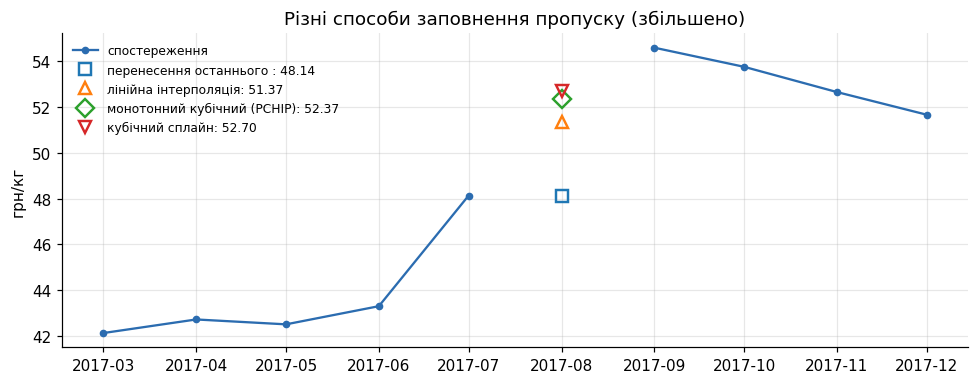


Ринки з нетиповими пропусками (без спільного пропуску 2017-08):
  Crimea           вимірів:  1;  відсутні: 2014-04…2017-07, 2017-09…2017-12  (44 міс.)
  m. Sevastopol    вимірів:  2;  відсутні: 2014-05…2017-07, 2017-09…2017-12  (43 міс.)
  Luhanska         вимірів: 40;  відсутні: 2014-08…2014-12  (5 міс.)
  Donetska         вимірів: 42;  відсутні: 2014-08…2014-09, 2014-12  (3 міс.)


In [5]:
CHOSEN = 'лінійна інтерполяція'
s = METHODS[CHOSEN](s_raw).rename('price')
assert s.notna().all() and len(s) == 46
print(f'Обрано: {CHOSEN};  {gap_date:%Y-%m} = {s[gap_date]:.4f} грн/кг')

fig, ax = plt.subplots(figsize=(9, 3.6))
zoom = slice('2017-03-01', '2017-12-01')
ax.plot(s_raw[zoom].index, s_raw[zoom].values, '-o', color='#2b6cb0', lw=1.5, ms=4, label='спостереження')
mk = dict(zip(METHODS, ['s', '^', 'D', 'v']))
for name, v in fills.items():
    ax.plot(gap_date, v, mk[name], ms=8, mfc='none', mew=1.6, label=f'{name}: {v:.2f}')
ax.set_title('Різні способи заповнення пропуску (збільшено)'); ax.set_ylabel('грн/кг')
ax.legend(frameon=False, fontsize=8, loc='upper left'); plt.tight_layout(); plt.show()

def month_runs(ds):
    runs, start, prev = [], None, None
    for d in ds:
        if start is None:
            start = prev = d
        elif d == prev + pd.offsets.MonthBegin(1):
            prev = d
        else:
            runs.append((start, prev)); start = prev = d
    if start is not None:
        runs.append((start, prev))
    return ', '.join(f'{a:%Y-%m}' if a == b else f'{a:%Y-%m}…{b:%Y-%m}' for a, b in runs)

print('\nРинки з нетиповими пропусками (без спільного пропуску', gap_date.strftime('%Y-%m') + '):')
for m in cnt[cnt != 45].index:
    have = set(raw[(raw['ринок'] == m) & (raw['товар'] == GOOD)]['date'])
    miss = [d for d in GRID if d not in have and d != gap_date]
    print(f'  {m:<16} вимірів: {len(have):>2};  відсутні: {month_runs(miss)}  ({len(miss)} міс.)')

>**Висновок до завдання 2:**
>
>**1. Значення, які дає кожен спосіб** (сусіди: липень 2017 — 48,14; вересень — 54,60 грн/кг):
>
>| Спосіб | Значення, грн/кг | MAE на перевірці, грн |
>|---|---|---|
>| перенесення останнього | 48,14 | 0,80 |
>| лінійна інтерполяція | 51,37 | 0,49 |
>| монотонний кубічний (PCHIP) | 52,37 | 0,43 |
>| кубічний сплайн | 52,70 | 0,45 |
>
>**2. Що обрано: лінійну інтерполяцію.** Перенесення останнього значення відкидаємо: на ряді, що зростає, воно систематично занижує (помилка в 1,6 раза більша, ніж у лінійної інтерполяції: 0,80 проти 0,49 грн; а вересневе значення вже 54,60, тобто «серпень = липень» суперечить даним з обох боків). Гладкі методи (PCHIP, сплайн) на 41 спостереженні виявилися трохи точнішими, але різниця з лінійним — близько 0,06 грн при стандартному відхиленні місячних змін ≈1,3 грн, тобто на практиці це в межах шуму. 
>
>До того ж перевірка йде здебільшого по спокійних ділянках, а пропуск припадає на **стрибок**, де кубічні методи «продовжують імпульс» і дають 52,4–52,7, тобто майже вересневий рівень, що є сильнішим припущенням, ніж просто «посередині». Лінійна інтерполяція робить найменше припущень, прозора й відтворювана. 
>
>**3. Коли заповнювати пропуск неприпустимо.** Інтерполяція виправдана, коли пропуск **короткий, випадковий і оточений вимірами з обох боків**. Неприпустима, коли відсутність даних *сама є інформацією* або ряд просто припиняється. У цьому ж наборі: **Крим** має 1 вимір (березень 2014), **Севастополь** — 2: після цього ряди обірвані на ~43 місяці, і «заповнення» означало б вигадування цін на ринках, яких у спостереженні вже немає. **Донецька** (бракує серпня–вересня та грудня 2014) і **Луганська** (серпень–грудень 2014, 5 місяців поспіль) втрачають дані в період бойових дій — пропуск невипадковий і довгий, а лінійна лінія між двома точками загладила б саме той період, коли ринок найсильніше змінювався. 

## Завдання 3. Візуальна розвідка

Побудуйте **не менше трьох** графіків свого ряду, які відповідають на різні питання.

**У звіті наведіть:**
1. для кожного графіка — яке питання він ставить і **чому обрано саме таку геометрію та шкалу**;
2. одну знахідку, якої ви не очікували до побудови графіків.

> 💡 **Підказка.** Графік без пояснення вибору форми не зараховується. Нагадування з лекції: геометрія — це твердження про дані.

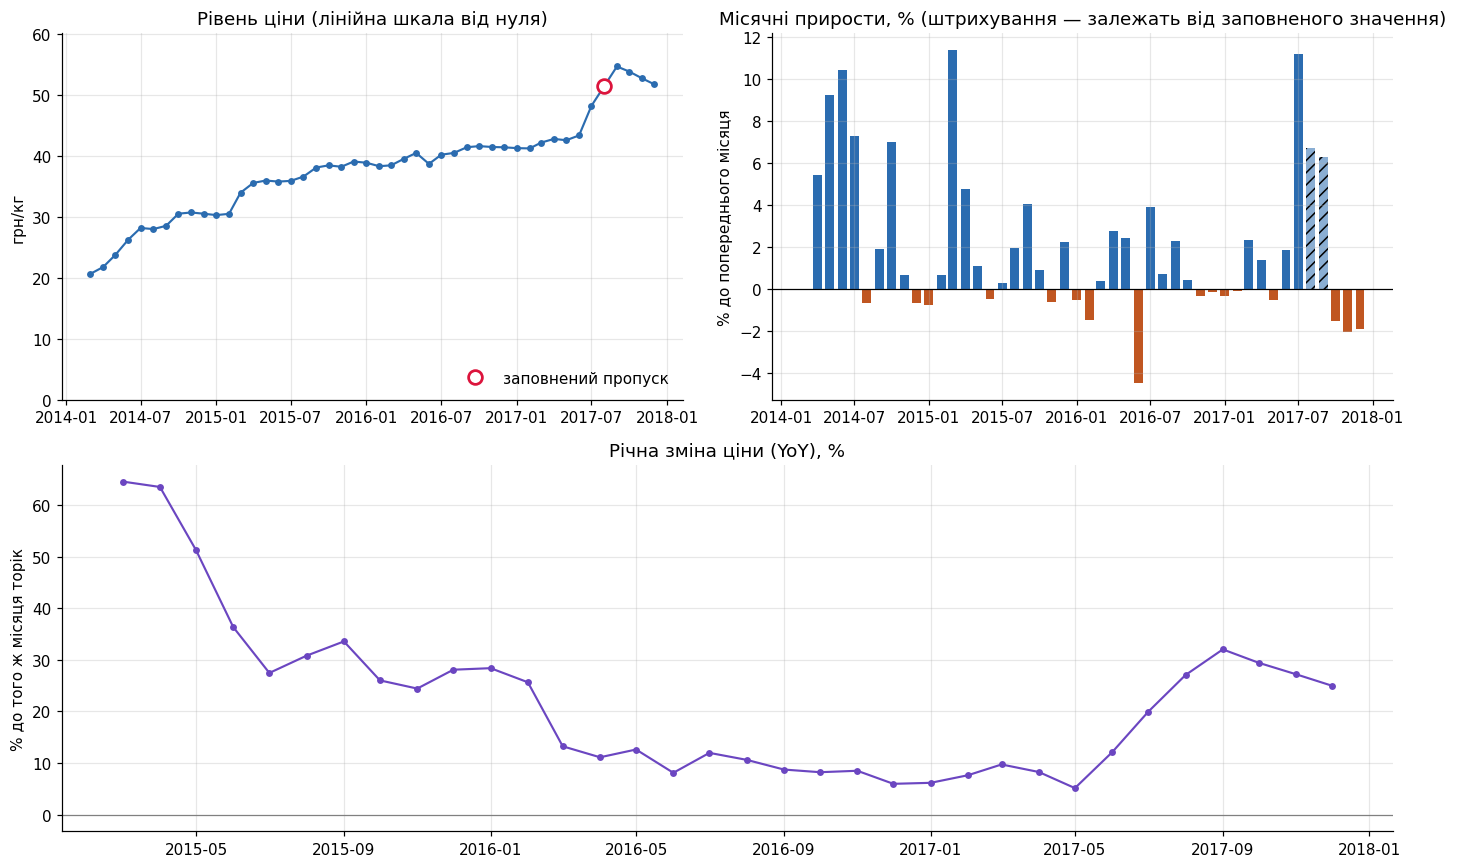

Ціна: 20.61 (бер 2014) → 51.67 (гру 2017), зростання ×2.51
Найбільші місячні прирости (без заповненого): 2015-03: +11.4%, 2017-07: +11.2%, 2014-06: +10.4%, 2014-05: +9.3%
Найбільші падіння: 2016-06: -4.5%, 2017-11: -2.1%, 2017-12: -1.9%

YoY: макс +64.5% (2015-03); мін +5.1% (2017-05) 
YoY у 2017-09: +32.0%
YoY за березень кожного року, %: {'2015': 64.5, '2016': 13.2, '2017': 9.7}


In [6]:
MON = ['січ', 'лют', 'бер', 'кві', 'тра', 'чер', 'лип', 'сер', 'вер', 'жов', 'лис', 'гру']
pct = s.pct_change() * 100           
yoy = s.pct_change(12) * 100         
imp_aff = [gap_date, gap_date + pd.offsets.MonthBegin(1)]   

fig, ax = plt.subplot_mosaic([['a', 'b'], ['c', 'c']], figsize=(13, 8))

a = ax['a']
a.plot(s.index, s.values, '-o', ms=3.5, lw=1.4, color='#2b6cb0')
a.plot(gap_date, s[gap_date], 'o', mfc='white', mec='crimson', ms=9, mew=1.8, label='заповнений пропуск')
a.set_ylim(0, s.max() * 1.1); a.set_ylabel('грн/кг'); a.legend(frameon=False, loc='lower right')
a.set_title('Рівень ціни (лінійна шкала від нуля)')

b = ax['b']
bars = b.bar(pct.index, pct.fillna(0).values, width=22,
             color=np.where(pct.fillna(0).values >= 0, '#2b6cb0', '#c05621'))
for bar, d in zip(bars, pct.index):
    if d in imp_aff:
        bar.set_hatch('///'); bar.set_alpha(0.55)
b.axhline(0, color='k', lw=0.8); b.set_ylabel('% до попереднього місяця')
b.set_title('Місячні прирости, % (штрихування — залежать від заповненого значення)')

c_ax = ax['c']
c_ax.plot(yoy.dropna().index, yoy.dropna().values, '-o', ms=3.5, lw=1.4, color='#6b46c1')
c_ax.axhline(0, color='grey', lw=0.8); c_ax.set_ylabel('% до того ж місяця торік')
c_ax.set_title('Річна зміна ціни (YoY), %')
plt.tight_layout(); plt.show()

print(f'Ціна: {s.iloc[0]:.2f} (бер 2014) → {s.iloc[-1]:.2f} (гру 2017), зростання ×{s.iloc[-1] / s.iloc[0]:.2f}')
top = pct.drop(imp_aff).sort_values(ascending=False).head(4)
print('Найбільші місячні прирости (без заповненого):', ', '.join(f'{d:%Y-%m}: {v:+.1f}%' for d, v in top.items()))
print('Найбільші падіння:', ', '.join(f'{d:%Y-%m}: {v:+.1f}%' for d, v in pct.sort_values().head(3).items()))
print(f'\nYoY: макс {yoy.max():+.1f}% ({yoy.idxmax():%Y-%m}); мін {yoy.min():+.1f}% ({yoy.idxmin():%Y-%m}) ')
print(f'YoY у {yoy.index[-4]:%Y-%m}: {yoy.iloc[-4]:+.1f}%')
print('YoY за березень кожного року, %:', {f'{d:%Y}': round(v, 1) for d, v in yoy[yoy.index.month == 3].dropna().items()})

>**Висновок до завдання 3:**
>
>| Графік | Питання | Чому така геометрія й шкала |
>|---|---|---|
>| **A.** Рівень | Як змінювався рівень ціни і в скільки разів вона зросла? | **Лінія з маркерами**: лінія показує неперервну траєкторію, маркери нагадують, що це дискретні місячні виміри (і де заповнена точка). **Лінійна шкала від нуля**, щоб відносне зростання (×2,51: 20,6 → 51,7 грн) не спотворювалося обрізаною віссю. |
>| **B.** Місячні прирости, % | Коли й наскільки різко ціна змінювалась? | **Стовпчики від нуля**: це знакові зміни, довжина стовпчика = величина зміни, нуль — змістовна точка відліку. Штрихуванням позначено два прирости, що залежать від заповненого значення. |
>| **С.** Річна зміна, % | Як змінювалася *швидкість* подорожчання? | **Лінія від нуля**: порівняння з тим самим місяцем торік прибирає сезонність і зводить зміни до порівнянної відсоткової шкали; нуль — орієнтир між подорожчанням і здешевленням. |
>
>**Знахідка, якої я не очікувала.** Асиметрія цінової динаміки (Графік B): На графіку місячних приростів стовпчики вгору (сині) значно переважають за амплітудою та частотою стовпчики вниз (помаранчеві). Здешевлення товару траплялося рідко і носило виключно коригувальний характер (не більше -2%...-4.5%), тоді як хвилі зростання легко досягали +9%...+11.4% за один місяць.
>
>Показник річного приросту (YoY) після шокового сплеску у березні 2015 року (+64.5%) демонстрував стійкий спад аж до травня 2017 року (всього +5.1%). Це свідчить про те, що ринок пристосувався до нових витрат, і лише нова хвиля собівартості в другій половині 2017 року знову підкинула річні темпи до +32%.

## Завдання 4. Розкладання на складові

Розкладіть ряд на тренд, сезонну складову та залишок методом STL із періодом 12.

**У звіті наведіть:**
1. чотирипанельний графік розкладання;
2. числові значення сили сезонності $F_S$ та сили тренду $F_T$;
3. **висновок: чи є у вашому ряді сезонність**, із посиланням на порогове значення.

> 💡 **Підказка.** STL поверне сезонну складову завжди. Ваше завдання — вирішити, чи вона означає щось, а не чи вона є.

In [1]:
%pip install statsmodels

   ---------------------------------------- 0.0/11.3 MB ? eta -:--:--
   ------------ --------------------------- 3.7/11.3 MB 29.6 MB/s eta 0:00:01
   ---------------------------------------  11.3/11.3 MB 36.4 MB/s eta 0:00:01
   ---------------------------------------- 11.3/11.3 MB 32.6 MB/s  0:00:00

   ---------------------------------------- 0/4 [patsy]
   ---------------------------------------- 0/4 [patsy]
   ---------------------------------------- 0/4 [patsy]
   ---------------------------------------- 0/4 [patsy]
   ---------------------------------------- 0/4 [patsy]
   ---------------------------------------- 0/4 [patsy]
   ---------------------------------------- 0/4 [patsy]
   ---------------------------------------- 0/4 [patsy]
   ---------- ----------------------------- 1/4 [interface-meta]
   ---------- ----------------------------- 1/4 [interface-meta]
   ---------- ----------------------------- 1/4 [interface-meta]
   -------------------- ------------------- 2/4 [form


[notice] A new release of pip is available: 26.0.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


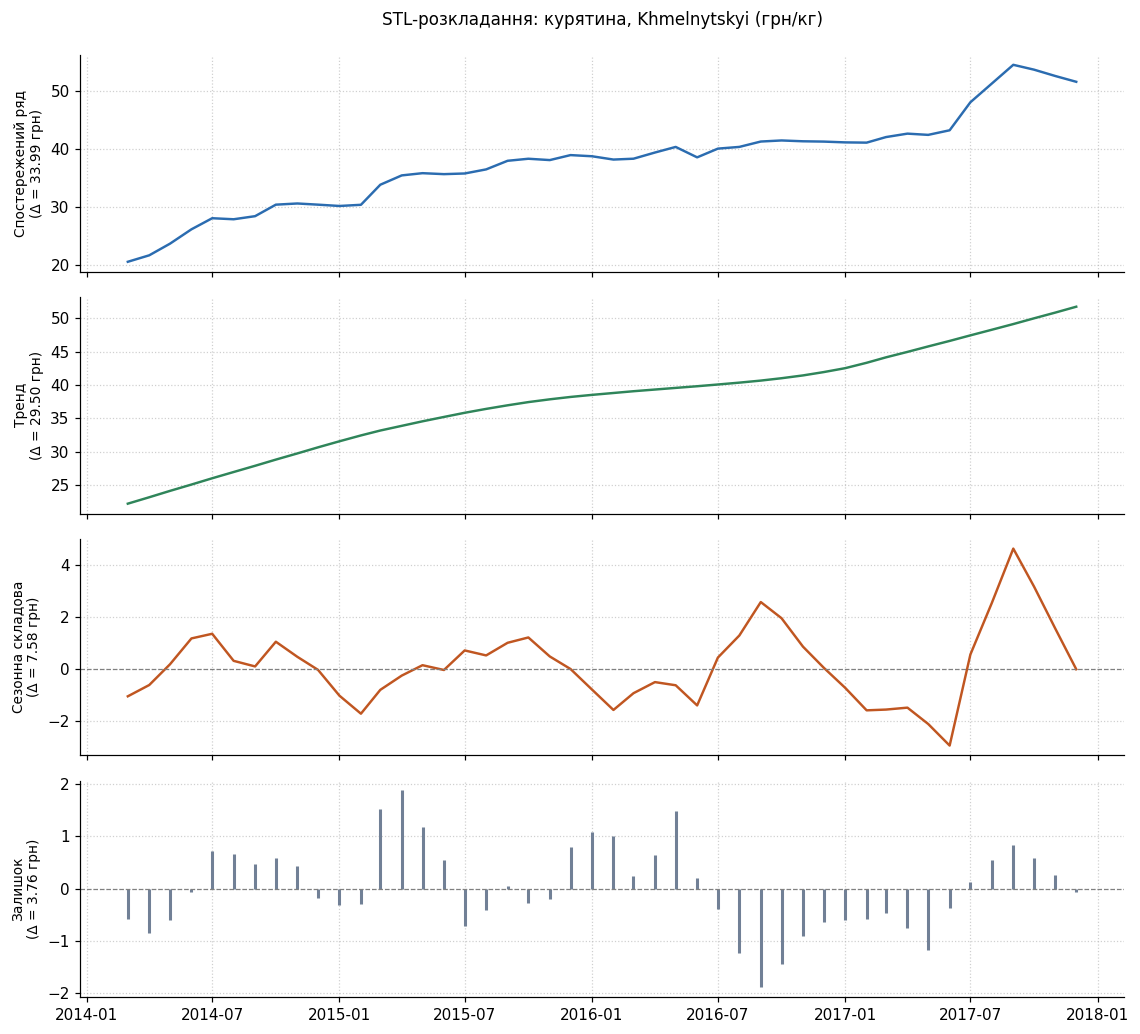

F_S (сила сезонності) = 0.763      F_T (сила тренду) = 0.989      поріг = 0.64

Сезонна складова за місяцями, грн/кг:
date
січ   -0.84
лют   -1.62
бер   -1.08
кві   -0.71
тра   -0.59
чер   -0.79
лип    0.78
сер    1.18
вер    2.09
жов    1.86
лис    0.85
гру    0.01

Розмах усієї сезонної складової: 7.58 грн;  розмах середнього сезонного профілю: 3.71 грн (≈ 10% від середньої ціни 37.9);  розмах тренду: 29.50 грн


In [7]:
from statsmodels.tsa.seasonal import STL
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

stl = STL(s, period=12).fit()
T, S, R = stl.trend, stl.seasonal, stl.resid

FS = max(0, 1 - R.var() / (S + R).var())
FT = max(0, 1 - R.var() / (T + R).var())
THR = 0.64        

components = [
    ('Спостережений ряд', s, '#2b6cb0'),
    ('Тренд', T, '#2f855a'),
    ('Сезонна складова', S, '#c05621'),
    ('Залишок', R, '#718096')
]

fig, axes = plt.subplots(4, 1, figsize=(10.5, 9.5), sharex=True)

for ax_, (name, comp, col) in zip(axes, components):
    span = comp.max() - comp.min()
    if name == 'Залишок':
        ax_.vlines(comp.index, 0, comp.values, color=col, lw=2)
    else:
        ax_.plot(comp.index, comp.values, color=col, lw=1.6)
    if name in ('Сезонна складова', 'Залишок'):
        ax_.axhline(0, color='grey', lw=0.8, ls='--')
    ax_.set_ylabel(f'{name}\n(Δ = {span:.2f} грн)', fontsize=9)
    ax_.grid(True, linestyle=':', alpha=0.6)

axes[0].set_title(f'STL-розкладання: {GOOD_UA}, {MARKET} (грн/кг)\n', fontsize=11)

plt.tight_layout()
plt.show()

print(f'F_S (сила сезонності) = {FS:.3f}      F_T (сила тренду) = {FT:.3f}      поріг = {THR}')
sm = S.groupby(S.index.month).mean()
print('\nСезонна складова за місяцями, грн/кг:')
print(sm.round(2).rename(dict(zip(range(1, 13), MON))).to_string())
print(f'\nРозмах усієї сезонної складової: {S.max() - S.min():.2f} грн;  розмах середнього сезонного профілю: '
      f'{sm.max() - sm.min():.2f} грн (≈ {(sm.max() - sm.min()) / s.mean() * 100:.0f}% від середньої ціни {s.mean():.1f});  розмах тренду: {T.max() - T.min():.2f} грн')

>**Висновок до завдання 4:**
>
>Сила сезонності **F_S = 0,763**, сила тренду **F_T = 0,989**; поріг «сильної» сезонності — **0,64**.
>
>**Формально** F_S > 0,64, тобто за порогом сезонність «є». Але STL повертає сезонну складову завжди, тому варто детальніше глянути на дані.
>
>Інші ознаки слабкості сезонного сигналу:
>* сезонна складова нестабільна: її пік (+4,6 грн) припадає на серпень–вересень 2017, тобто STL віднесла до сезонності **стрибок 2017 року**, без цього піку розкид був би помірним;
>* середній сезонний профіль має розмах лише 3,7 грн (≈10 % середньої ціни) на тлі розмаху тренду 29,5 грн: низькі січень–червень (−0,6…−1,6), вищі липень–листопад (до +2,1 у вересні);
>* ряд охоплює лише ≈3,8 року, тож кожен календарний місяць оцінено по 3–4 точках.
>
>**Висновок:** сезонність у ряді **формально сильна за порогом, але статистично не доведена**; є слабка схильність до дорожчання з липня до жовтня, що потребує довшого ряду для підтвердження. Тренд, навпаки, домінує однозначно (F_T = 0,99).

## Завдання 5. Стаціонарність

Побудуйте ACF і PACF вихідного ряду та його першої різниці. Застосуйте тести ADF і KPSS до обох.

**У звіті наведіть:**
1. графіки ACF і PACF до та після диференціювання;
2. таблицю з $p$-значеннями обох тестів для обох рядів;
3. висновок про стаціонарність **із зазначенням, узгоджуються тести між собою чи ні**;
4. якщо не узгоджуються — ваше пояснення, чому.

> 💡 **Підказка.** Нульові гіпотези ADF і KPSS протилежні. Перш ніж писати висновок, перевірте, що ви не переплутали напрямок.

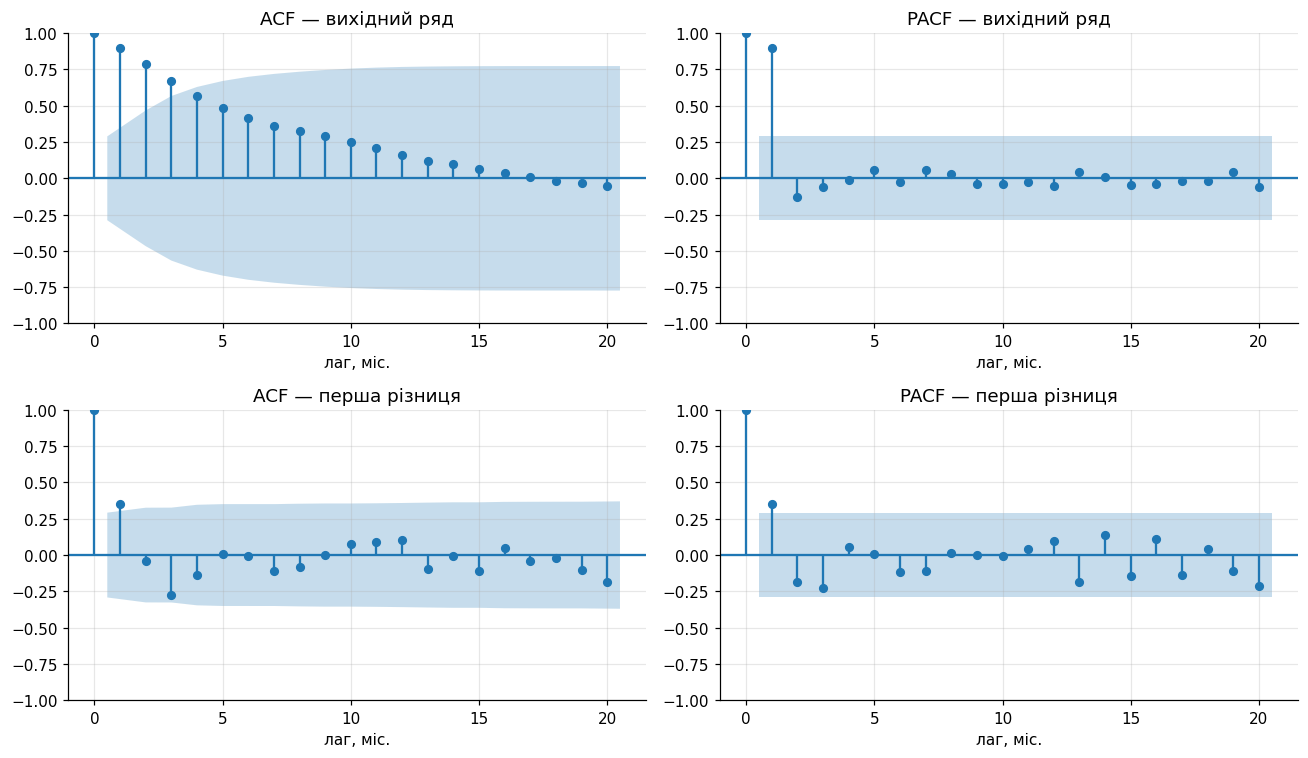

вихідний ряд: межа ±0.289
   значущі лаги ACF : [(1, 0.9), (2, 0.78), (3, 0.67), (4, 0.57), (5, 0.48), (6, 0.41), (7, 0.36), (8, 0.33), (9, 0.29)]
   значущі лаги PACF: [(1, 0.9)]
перша різниця: межа ±0.292
   значущі лаги ACF : [(1, 0.35)]
   значущі лаги PACF: [(1, 0.35)]

p-значення тестів (KPSS: p обмежене діапазоном таблиці [0.01; 0.10]):
               ADF, p (const)  ADF, p (const+trend)  KPSS, p (рівень)  KPSS, p (тренд)
вихідний ряд           0.5642                 0.067              0.01              0.1
перша різниця          0.0002                 0.002              0.10              0.1

Висновок за рівнем значущості 5%:
  вихідний ряд   | «const»        : НЕстаціонарний (тести узгоджуються)
                 | «const+trend»  : тести суперечать один одному
  перша різниця  | «const»        : стаціонарний (тести узгоджуються)
                 | «const+trend»  : стаціонарний (тести узгоджуються)


In [8]:
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.stattools import adfuller, kpss, acf, pacf

d1 = s.diff().dropna().rename('Δprice')
NL = 20

fig, axes = plt.subplots(2, 2, figsize=(12, 7))
plot_acf(s,  lags=NL, ax=axes[0, 0], title='ACF — вихідний ряд')
plot_pacf(s, lags=NL, ax=axes[0, 1], method='ywm', title='PACF — вихідний ряд')
plot_acf(d1, lags=NL, ax=axes[1, 0], title='ACF — перша різниця')
plot_pacf(d1, lags=NL, ax=axes[1, 1], method='ywm', title='PACF — перша різниця')
for a_ in axes.ravel():
    a_.set_xlabel('лаг, міс.')
plt.tight_layout(); plt.show()

def sig_lags(x, kind, nl=12):
    vals = (acf(x, nlags=nl) if kind == 'acf' else pacf(x, nlags=nl, method='ywm'))[1:]
    bound = 1.96 / np.sqrt(len(x))
    return [(i + 1, round(float(v), 2)) for i, v in enumerate(vals) if abs(v) > bound], bound

for name, x in [('вихідний ряд', s), ('перша різниця', d1)]:
    la, bnd = sig_lags(x, 'acf'); lp, _ = sig_lags(x, 'pacf')
    print(f'{name}: межа ±{bnd:.3f}\n   значущі лаги ACF : {la}\n   значущі лаги PACF: {lp}')

def tests(x):
    with warnings.catch_warnings():        
        warnings.simplefilter('ignore')
        return {
            'ADF, p (const)':       adfuller(x, regression='c',  autolag='AIC')[1],
            'ADF, p (const+trend)': adfuller(x, regression='ct', autolag='AIC')[1],
            'KPSS, p (рівень)':     kpss(x, regression='c',  nlags='auto')[1],
            'KPSS, p (тренд)':      kpss(x, regression='ct', nlags='auto')[1],
        }
tab = pd.DataFrame({'вихідний ряд': tests(s), 'перша різниця': tests(d1)}).T
print('\np-значення тестів (KPSS: p обмежене діапазоном таблиці [0.01; 0.10]):')
print(tab.round(4).to_string())

def verdict(adf_p, kpss_p, a=0.05):
    adf_stat, kpss_stat = adf_p < a, kpss_p >= a     
    if adf_stat and kpss_stat:   return 'стаціонарний (тести узгоджуються)'
    if not adf_stat and not kpss_stat: return 'НЕстаціонарний (тести узгоджуються)'
    return 'тести суперечать один одному'
print('\nВисновок за рівнем значущості 5%:')
for name in tab.index:
    print(f'  {name:<14} | «const»        : {verdict(tab.loc[name, "ADF, p (const)"], tab.loc[name, "KPSS, p (рівень)"])}')
    print(f'  {"":<14} | «const+trend»  : {verdict(tab.loc[name, "ADF, p (const+trend)"], tab.loc[name, "KPSS, p (тренд)"])}')

**Висновок до завдання 5:**

>**Графіки.** *Вихідний ряд:* ACF повільно згасає (дев'ять значущих лагів, від 0,90 на лазі 1 до 0,29 на лазі 9), PACF має єдиний значущий лаг 1 (0,90) — класична картина ряду з трендом / одиничним коренем. *Перша різниця:* і ACF, і PACF мають **лише лаг 1 = 0,35** (межа ±0,29); лаг 3 (−0,28 / −0,24) на межі смуги, але всередині.
>
>**p-значення тестів** (ADF: H₀ — одиничний корінь, ряд нестаціонарний; KPSS: H₀ — ряд стаціонарний; p KPSS обмежене діапазоном таблиці 0,01–0,10):
>
>| | ADF (const) | ADF (const+trend) | KPSS (рівень) | KPSS (тренд) |
>|---|---|---|---|---|
>| вихідний ряд | 0,564 | 0,067 | ≤ 0,01 | ≥ 0,10 |
>| перша різниця | 0,0002 | 0,002 | ≥ 0,10 | ≥ 0,10 |
>
>**Висновок про стаціонарність.**
>* **Вихідний ряд нестаціонарний, тести узгоджуються**: ADF не відхиляє одиничний корінь (p = 0,56), KPSS відхиляє стаціонарність (p ≤ 0,01) — обидва говорять «нестаціонарний».
>* **Перша різниця стаціонарна, тести узгоджуються**: ADF відхиляє одиничний корінь (p = 0,0002), KPSS не відхиляє стаціонарності (p ≥ 0,10). Звідси **d = 1**.
>
>**Де тести розходяться.** У специфікації «константа + тренд» картина для вихідного ряду неоднозначна: ADF не відхиляє одиничний корінь на 5 % (p = 0,067, але відхилив би на 10 %), а KPSS не відхиляє стаціонарності навколо тренду (p ≥ 0,10) — тести суперечать один одному. Пояснення: за 46 точок ADF має низьку потужність і не здатний надійно відрізнити «ряд із одиничним коренем» від «стаціонарного навколо тренду»; крім того, **структурні стрибки** (2015, 2017) зміщують ADF до недовідхилення, а KPSS — до відхилення. Тому замість того щоб робити висновки про тип нестаціонарності, а вибираю диференціювання (d = 1) як безпечніший варіант: надлишкове диференціювання шкодить менше, ніж пропущений одиничний корінь, і перша різниця проходить обидва тести в усіх специфікаціях.

## Завдання 6. Базисні прогнози та ретроспективна перевірка

Побудуйте **чотири** базисні прогнози: наївний, сезонний наївний, середнє та дрейф.
Оцініть їх **ретроспективною перевіркою з рухомим початком**: **7 фолдів по 3 кроки**,
навчальна частина розширюється.

**У звіті наведіть:**
1. таблицю MAE, RMSE і MAPE для всіх чотирьох базисів;
2. який базис виявився найкращим і **чому саме він** — поясніть через властивості вашого ряду;
3. для порівняння: ту саму оцінку, зроблену звичайним випадковим поділом 75/25, і **у скільки разів** вона відрізняється.

> 💡 **Підказка.** Кількість фолдів і кроків задана жорстко — у Частині 2 вона має збігтися з налаштуваннями Orange.

In [10]:
H, K = 3, 7                                  
y, dates, N = s.values, s.index, len(s)
FIRST_TRAIN = N - K * H                    
ORIGINS = [FIRST_TRAIN + k * H for k in range(K)]  

print('Фолди (навчання розширюється, тестові відрізки не перетинаються):')
for k, Tn in enumerate(ORIGINS, 1):
    print(f'  фолд {k}: навчання {dates[0]:%Y-%m}…{dates[Tn - 1]:%Y-%m} ({Tn} міс.) → тест {dates[Tn]:%Y-%m}…{dates[Tn + H - 1]:%Y-%m}')

def fc_naive(tr, h):  return np.repeat(tr[-1], h)
def fc_snaive(tr, h, m=12): return np.array([tr[len(tr) - m + (i % m)] for i in range(h)])
def fc_mean(tr, h):   return np.repeat(tr.mean(), h)
def fc_drift(tr, h):  return tr[-1] + (tr[-1] - tr[0]) / (len(tr) - 1) * np.arange(1, h + 1)

BASELINES = {'наївний': fc_naive, 'сезонний наївний': fc_snaive, 'середнє': fc_mean, 'дрейф': fc_drift}

def collect(forecaster):
    """Усі прогнози ретроспективної перевірки в довгій таблиці: фолд, крок, дата, факт, прогноз."""
    rows = []
    for k, Tn in enumerate(ORIGINS, 1):
        pred = forecaster(y[:Tn], H)
        for h in range(H):
            rows.append(dict(fold=k, h=h + 1, date=dates[Tn + h], actual=y[Tn + h], pred=pred[h]))
    return pd.DataFrame(rows)

def metrics(df):
    e = df['actual'] - df['pred']
    return {'MAE': e.abs().mean(), 'RMSE': np.sqrt((e ** 2).mean()), 'MAPE, %': (e.abs() / df['actual']).mean() * 100}

fc = {name: collect(f) for name, f in BASELINES.items()}
res6 = pd.DataFrame({name: metrics(df) for name, df in fc.items()}).T
print(f'\nМетрики по {K * H} прогнозах (усі помилки об\'єднано):')
print(res6.round(3).to_string())
best = res6['MAE'].idxmin()
print(f'\nНайкращий базис за MAE: «{best}»;  за RMSE: «{res6["RMSE"].idxmin()}»;  за MAPE: «{res6["MAPE, %"].idxmin()}»')

no_imp = pd.DataFrame({n: metrics(df[df['date'] != gap_date]) for n, df in fc.items()}).T
print(f'\nТой самий підрахунок без заповненої точки {gap_date:%Y-%m} (тестових точок {K * H - 1}):')
print(no_imp.round(3).to_string())

by_h = fc[best].assign(ae=lambda d: (d['actual'] - d['pred']).abs()).groupby('h')['ae'].mean()
print(f'\nMAE «{best}» за кроком горизонту:', by_h.round(2).to_dict())

Фолди (навчання розширюється, тестові відрізки не перетинаються):
  фолд 1: навчання 2014-03…2016-03 (25 міс.) → тест 2016-04…2016-06
  фолд 2: навчання 2014-03…2016-06 (28 міс.) → тест 2016-07…2016-09
  фолд 3: навчання 2014-03…2016-09 (31 міс.) → тест 2016-10…2016-12
  фолд 4: навчання 2014-03…2016-12 (34 міс.) → тест 2017-01…2017-03
  фолд 5: навчання 2014-03…2017-03 (37 міс.) → тест 2017-04…2017-06
  фолд 6: навчання 2014-03…2017-06 (40 міс.) → тест 2017-07…2017-09
  фолд 7: навчання 2014-03…2017-09 (43 міс.) → тест 2017-10…2017-12

Метрики по 21 прогнозах (усі помилки об'єднано):
                    MAE    RMSE  MAPE, %
наївний           2.036   3.450    4.224
сезонний наївний  5.554   6.624   11.877
середнє           9.722  10.506   21.292
дрейф             2.136   3.223    4.435

Найкращий базис за MAE: «наївний»;  за RMSE: «дрейф»;  за MAPE: «наївний»

Той самий підрахунок без заповненої точки 2017-08 (тестових точок 20):
                    MAE    RMSE  MAPE, %
наївний        

In [11]:
def rand_forecast(method, tr_idx, te_idx):
    tr_idx = np.sort(tr_idx); tr_set = set(tr_idx.tolist()); out = []
    for t in te_idx:
        earlier = tr_idx[tr_idx < t]
        last_i = earlier[-1] if len(earlier) else tr_idx[0]
        if method == 'наївний':            p = y[last_i]
        elif method == 'сезонний наївний': p = y[t - 12] if (t - 12) in tr_set else y[last_i]
        elif method == 'середнє':          p = y[tr_idx].mean()
        else: 
            i0, i1 = tr_idx[0], tr_idx[-1]; p = y[i0] + (y[i1] - y[i0]) / (i1 - i0) * (t - i0)
        out.append(p)
    return np.array(out)

n_test = int(np.ceil(0.25 * N))            

def rand_metrics(seed):
    rng_ = np.random.default_rng(seed)
    perm = rng_.permutation(N); te, tr = perm[:n_test], perm[n_test:]
    out = {}
    for name in BASELINES:
        e = y[te] - rand_forecast(name, tr, te)
        out[name] = {'MAE': np.abs(e).mean(), 'RMSE': np.sqrt((e ** 2).mean()),
                     'MAPE, %': (np.abs(e) / y[te]).mean() * 100}
    return out

one = pd.DataFrame(rand_metrics(RNG_SEED)).T
many = np.array([[m[name]['MAE'] for name in BASELINES] for m in (rand_metrics(sd) for sd in range(1000))])
cmp6 = pd.DataFrame({
    'MAE, рухомий початок': res6['MAE'],
    'MAE, випадковий (seed 42)': one['MAE'],
    'MAE, випадковий (медіана з 1000)': pd.Series(np.median(many, axis=0), index=BASELINES),
})
cmp6['у скільки разів (рух./випадк., медіана)'] = cmp6['MAE, рухомий початок'] / cmp6['MAE, випадковий (медіана з 1000)']
print(f'Випадковий поділ 75/25: {N - n_test} навчальних і {n_test} тестових точок')
print(cmp6.round(3).to_string())
print('\nМетрики випадкового поділу (seed 42):'); print(one.round(3).to_string())
print(f'\nНайкращий базис «{best}»: рухомий початок дає MAE {res6.loc[best, "MAE"]:.2f}, '
      f'випадковий поділ — {np.median(many, axis=0)[list(BASELINES).index(best)]:.2f} (медіана 1000 поділів): '
      f'оцінка завищує якість у {cmp6.loc[best, "у скільки разів (рух./випадк., медіана)"]:.1f} раза(ів).')

Випадковий поділ 75/25: 34 навчальних і 12 тестових точок
                  MAE, рухомий початок  MAE, випадковий (seed 42)  MAE, випадковий (медіана з 1000)  у скільки разів (рух./випадк., медіана)
наївний                          2.036                      1.029                             1.172                                    1.738
сезонний наївний                 5.554                      5.380                             4.407                                    1.260
середнє                          9.722                      6.993                             6.349                                    1.531
дрейф                            2.136                      2.248                             2.874                                    0.743

Метрики випадкового поділу (seed 42):
                    MAE   RMSE  MAPE, %
наївний           1.029  1.355    2.640
сезонний наївний  5.380  6.324   12.565
середнє           6.993  8.784   16.312
дрейф             2.248  2.702    6.09

>**Висновок до завдання 6:**
>
>**Схема перевірки.** 7 фолдів по 3 кроки; навчальна вибірка розширюється: фолд 1 навчається на березні 2014 — березні 2016 (25 міс.) і прогнозує квітень–червень 2016, … фолд 7 навчається до вересня 2017 (43 міс.) і прогнозує жовтень–грудень 2017. Усього 21 прогноз; метрики пораховано по всіх помилках разом.
>
>| Базис | MAE, грн | RMSE, грн | MAPE, % |
>|---|---|---|---|
>| **наївний** | **2,04** | 3,45 | **4,22** |
>| сезонний наївний | 5,55 | 6,62 | 11,88 |
>| середнє | 9,72 | 10,51 | 21,29 |
>| дрейф | 2,14 | **3,22** | 4,44 |
>
>**Найкращий базис — наївний** (за MAE та MAPE; за RMSE трохи випереджає дрейф: 3,22 проти 3,45, тобто фактично нічия). Чому саме він:
>* ряд поводиться як **випадкове блукання**: PACF рівня має єдиний лаг 0,90, а різниці майже некорельовані (лише лаг 1 = 0,35), тож найкраща оцінка наступного значення — останнє відоме;
>* **дрейф** рахує нахил по всій історії, зокрема по швидкому зростанню 2014–2015, тоді як у 2016–2017 ціна росла повільніше (крім стрибка 2017), тому він переоцінює; щоправда, він трохи виграє за RMSE, бо частково «наздоганяє» стрибок 2017 року;
>* **сезонний наївний** у 2,7 раза гірший: копіюючи значення річної давності, він ігнорує, що ціна за рік зростає на 5–30 % — річний тренд значно більший за можливий сезонний сигнал
>* **середнє** найгірше (9,72), бо ряд трендовий і середнє всієї історії завжди далеко від поточного рівня.
>
 >**Чутливість:** одна із 21 тестових точок (серпень 2017) — заповнене значення; без неї метрики нижчі (наївний MAE 1,74, дрейф 1,90), але порядок базисів не змінюється.
>
>**Випадковий поділ 75/25** (34 навчальні, 12 тестових точок; кожен базис адаптовано до цієї постановки: «останнє значення» — найближче раніше навчальне, дрейф — пряма через перше й останнє навчальні спостереження; для надійності взято медіану з 1000 різних поділів, при seed 42 — 1,03). 
>
>Для найкращого базису (наївний) MAE на випадковому поділі = **1,17 грн** проти **2,04 грн** на рухомому початку, тобто **ретроспективна перевірка дає у 1,7 раза більшу помилку**: випадковий поділ занижує реальну похибку майже вдвічі. Для інших базисів відношення таке: 
>* сезонний наївний — 1,26, 
>* середнє — 1,53; 
>* дрейф — навпаки, 0,74 (на випадковому поділі він гірший). 
>
>Причина у витоку майбутнього: на випадковому поділі «останнє відоме значення» в середньому лише на ≈1,3 місяця старіше за тестову точку (на справжньому прогнозі — 1–3 місяці) і серед навчальних даних є точки *після* тестової. Побічний ефект — спотворення порівняння методів: на рухомому початку наївний і дрейф майже рівні (2,04 і 2,14), а на випадковому наївний здається вдвічі кращим (1,17 проти 2,87). Результат залежить від того, як адаптовано базиси до випадкового поділу, але напрямок ефекту (завищення якості) не залежить від цього вибору.

## Завдання 7. Модель ARIMA

Побудуйте модель ARIMA і оцініть її **на тих самих 7 фолдах по 3 кроки**.

Обов'язково використайте порядок **(1, 1, 1)** — саме його ви відтворюватимете в Orange.
Додатково визначте, який порядок $(p, d, q)$ ви обрали б **за виглядом ACF і PACF** із завдання 5.

**У звіті наведіть:**
1. MAE, RMSE і MAPE моделі ARIMA(1,1,1) на рухомому початку;
2. обґрунтування порядку, який ви обрали б самостійно, з посиланням на конкретні лаги;
3. **порівняння з найкращим базисом із завдання 6** — і прямий висновок, чи має ця модель право на існування;
4. графік залишків моделі та висновок, чи лишилася в них структура.

> 💡 **Підказка.** Якщо ARIMA програла базису — це законний результат, а не помилка. Напишіть про це прямо.

In [12]:
from statsmodels.tsa.arima.model import ARIMA

def fc_arima(order, trend='n'):
    def f(tr, h):
        return np.asarray(ARIMA(tr, order=order, trend=trend).fit().forecast(h))
    return f

def fc_arima_drift(tr, h):
    r = ARIMA(np.diff(tr), order=(1, 0, 1), trend='c').fit()
    return tr[-1] + np.cumsum(np.asarray(r.forecast(h)))

df_ar = collect(fc_arima((1, 1, 1)))
df_ard = collect(fc_arima_drift)
fc_all = {**fc, 'ARIMA(1,1,1)': df_ar, 'ARIMA(1,1,1) + дрейф (додатково)': df_ard}
res7 = pd.DataFrame({n: metrics(d) for n, d in fc_all.items()}).T
print('1) Метрики на рухомому початку (7 фолдів × 3 кроки, 21 прогноз):')
print(res7.round(3).to_string())

mae_fold = lambda d: d.assign(ae=(d['actual'] - d['pred']).abs()).groupby('fold')['ae'].mean()
cmp7 = pd.DataFrame({'ARIMA(1,1,1)': mae_fold(df_ar), f'{best}': mae_fold(fc[best])})
cmp7['переможець'] = np.where(cmp7['ARIMA(1,1,1)'] < cmp7[best], 'ARIMA', best)
print(f'\n2) MAE по фолдах: ARIMA(1,1,1) проти «{best}»')
print(cmp7.round(2).to_string())
print(f'ARIMA виграє у {(cmp7["переможець"] == "ARIMA").sum()} із {K} фолдів;  '
      f'відношення MAE ARIMA/{best} = {res7.loc["ARIMA(1,1,1)", "MAE"] / res7.loc[best, "MAE"]:.2f}')
no_imp7 = pd.DataFrame({n: metrics(d[d['date'] != gap_date]) for n, d in fc_all.items()}).T.loc[[best, 'ARIMA(1,1,1)']]
print(f'\nБез заповненої точки {gap_date:%Y-%m}:'); print(no_imp7.round(3).to_string())

fit_full = ARIMA(s.values, order=(1, 1, 1), trend='n').fit()
print('\nПараметри ARIMA(1,1,1) на всьому ряді:')
print(pd.DataFrame({'оцінка': fit_full.params, 'p-значення': fit_full.pvalues},
                   index=['AR(1)', 'MA(1)', 'σ²']).round(4).to_string())

1) Метрики на рухомому початку (7 фолдів × 3 кроки, 21 прогноз):
                                    MAE    RMSE  MAPE, %
наївний                           2.036   3.450    4.224
сезонний наївний                  5.554   6.624   11.877
середнє                           9.722  10.506   21.292
дрейф                             2.136   3.223    4.435
ARIMA(1,1,1)                      2.825   4.312    5.827
ARIMA(1,1,1) + дрейф (додатково)  2.477   3.464    5.192

2) MAE по фолдах: ARIMA(1,1,1) проти «наївний»
      ARIMA(1,1,1)  наївний переможець
fold                                  
1             0.92     1.11      ARIMA
2             3.48     2.01    наївний
3             0.43     0.08    наївний
4             0.36     0.37      ARIMA
5             0.32     0.72      ARIMA
6             7.66     8.07      ARIMA
7             6.60     1.90    наївний
ARIMA виграє у 4 із 7 фолдів;  відношення MAE ARIMA/наївний = 1.39

Без заповненої точки 2017-08:
                MAE   RMSE  MAPE, %
наї

In [13]:
print('Значущі лаги першої різниці (із завдання 5):')
print('   ACF :', sig_lags(d1, 'acf')[0], ' | PACF:', sig_lags(d1, 'pacf')[0], f' | межа ±{sig_lags(d1, "acf")[1]:.3f}')

def aicc(res, n):
    k = len(res.params)
    return res.aic + 2 * k * (k + 1) / (n - k - 1)

cand = []
for p in range(3):
    for q in range(3):
        try:
            with warnings.catch_warnings():
                warnings.simplefilter('ignore')
                r = ARIMA(s.values, order=(p, 1, q), trend='n').fit()
            cand.append({'порядок': f'({p},1,{q})', 'AIC': r.aic, 'AICc': aicc(r, N - 1), 'BIC': r.bic})
        except Exception as ex:
            pass
cand = pd.DataFrame(cand).set_index('порядок').sort_values('AICc').round(2)
print('\nПорівняння порядків із d = 1 за інформаційними критеріями (менше — краще):')
print(cand.to_string())

Значущі лаги першої різниці (із завдання 5):
   ACF : [(1, 0.35)]  | PACF: [(1, 0.35)]  | межа ±0.292

Порівняння порядків із d = 1 за інформаційними критеріями (менше — краще):
            AIC    AICc     BIC
порядок                        
(1,1,0)  152.77  153.05  156.38
(0,1,2)  153.63  154.22  159.05
(2,1,0)  154.60  155.18  160.02
(1,1,1)  154.64  155.23  160.06
(0,1,1)  155.16  155.44  158.77
(1,1,2)  155.63  156.63  162.86
(2,1,1)  156.56  157.56  163.78
(2,1,2)  157.15  158.68  166.18
(0,1,0)  163.81  163.90  165.61


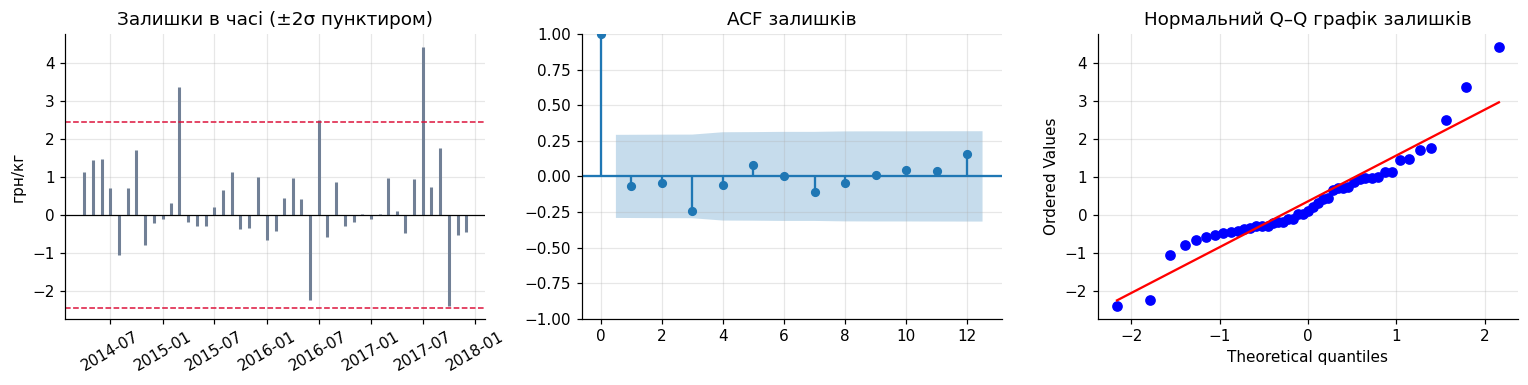

Тест Люнґа–Бокса на автокореляцію залишків (H0: залишки — білий шум):
    lb_stat  lb_pvalue
6    3.7481     0.4412
12   6.3412     0.7858

Залишки за межами ±2σ: 2015-03: +3.35, 2016-07: +2.49, 2017-07: +4.41
Середній залишок +0.349;  Шапіро–Вілк p = 0.0084


In [14]:
from statsmodels.stats.diagnostic import acorr_ljungbox
from scipy import stats

resid = pd.Series(fit_full.resid[1:], index=s.index[1:])
fig, axes = plt.subplots(1, 3, figsize=(14, 3.6))
axes[0].vlines(resid.index, 0, resid.values, color='#718096', lw=2)
axes[0].axhline(0, color='k', lw=0.8)
axes[0].axhline(2 * resid.std(), color='crimson', ls='--', lw=1); axes[0].axhline(-2 * resid.std(), color='crimson', ls='--', lw=1)
axes[0].set_title('Залишки в часі (±2σ пунктиром)'); axes[0].set_ylabel('грн/кг'); axes[0].tick_params(axis='x', rotation=30)
plot_acf(resid, lags=12, ax=axes[1], title='ACF залишків')
stats.probplot(resid, dist='norm', plot=axes[2]); axes[2].set_title('Нормальний Q–Q графік залишків')
plt.tight_layout(); plt.show()

lb = acorr_ljungbox(resid, lags=[6, 12], model_df=2, return_df=True)
print('Тест Люнґа–Бокса на автокореляцію залишків (H0: залишки — білий шум):')
print(lb.round(4).to_string())
out = resid[resid.abs() > 2 * resid.std()]
print('\nЗалишки за межами ±2σ:', ', '.join(f'{d:%Y-%m}: {v:+.2f}' for d, v in out.items()))
print(f'Середній залишок {resid.mean():+.3f};  Шапіро–Вілк p = {stats.shapiro(resid)[1]:.4f}')

>**Висновок до завдання 7:**
>
>**1. Метрики ARIMA(1,1,1)** (рухомий початок, 7 фолдів × 3 кроки, без константи): **MAE = 2,83 грн, RMSE = 4,31 грн, MAPE = 5,83 %**.
>
>**2. Який порядок я обрала би за ACF/PACF.** Спочатку **d = 1** (завдання 5: різниця стаціонарна). У першій різниці значущий **лише лаг 1** — і в ACF (0,35), і в PACF (0,35) при межі ±0,29; лаги 2 і далі - обидві функції «обриваються» після лага 1, що однаково відповідає AR(1) і MA(1), і за виглядом графіків їх не розрізнити. Я взяла би **ARIMA(1,1,0)** — найпростіша модель із одним параметром; інформаційні критерії це підтверджують: AICc = 153,05 (найнижчий), BIC = 156,38 (найнижчий); ARIMA(0,1,1) поступається за AICc на ≈2,4 пункти, ARIMA(1,1,1) — на ≈2,2 (BIC гірший на ≈3,7). У підігнаній (1,1,1) параметр MA(1) = 0,09 (p = 0,79) незначущий, AR(1) = 0,44 (p = 0,10) — на межі, тож (1,1,1) має зайвий параметр.
>
>**3. Порівняння з найкращим базисом (наївним).**
>
>| | MAE | RMSE | MAPE, % |
>|---|---|---|---|
>| наївний | **2,04** | **3,45** | **4,22** |
>| ARIMA(1,1,1) | 2,83 | 4,31 | 5,83 |
>| ARIMA(1,1,1) + дрейф | 2,48 | 3,46 | 5,19 |
>
>ARIMA(1,1,1) **програє наївному за всіма трьома метриками**: MAE на 39 % більший, RMSE на 25 %, MAPE на 38 %. По фолдах ARIMA виграє в 4 із 7, але перемоги дрібні (різниця до 0,4 грн), а втрати великі — фолд 7: 6,60 проти 1,90 грн, фолд 2: 3,48 проти 2,01. Причина: AR-складова екстраполює інерцію останніх змін; у фолді 7 навчання закінчується одразу після стрибка 2017 року, модель очікує продовження зростання, а ціна пішла вниз. 
>
>**Пряма відповідь: для цього ряду ARIMA(1,1,1) не має права на існування як робочий прогноз** — вона складніша й гірша за наївний. Навіть із дрейфом (додатково) 2,48 > 2,04. 
>
>**4. Залишки.** Автокореляції в них не лишилось: Люнґ–Бокс p = 0,44 (лаг 6) і 0,79 (лаг 12), усі лаги ACF у смузі. Тобто лінійну динаміку модель вичерпала. Але **структура лишилась іншого роду**: три залишки виходять за ±2σ, і **всі додатні** — березень 2015 (+3,35), липень 2016 (+2,49), липень 2017 (+4,41), тобто модель систематично не передбачає стрибки вгору; розподіл має важкий правий хвіст (Q–Q графік, Шапіро–Вілк p = 0,008, нормальність відхилено); середній залишок +0,35 свідчить про зміщення через відсутній дрейф (додавання дрейфу покращило MAE з 2,83 до 2,48). Отже, довірчі інтервали на основі нормальності були б ненадійні.

## Завдання 8. Точка зміни режиму

Знайдіть у своєму ряді точку, після якої змінюється **рівень** ряду.
Скористайтеся скануванням: для кожної кандидатної дати порівняйте середні до і після
та оберіть дату з найбільшою t-статистикою.

**У звіті наведіть:**
1. графік ряду з позначеною знайденою датою;
2. дату, значення t-статистики, середні рівні до і після;
3. **чи є ця точка значущою** — і якщо ні, так і напишіть;
4. чим знайдена точка відрізняється від звичайного сезонного сплеску у вашому ряді.

> 💡 **Підказка.** Не плутайте зсув рівня з сезонним піком. Якщо «аномалії» повторюються щороку в ті самі місяці — це сезон.

Знайдена дата (перший місяць «нового режиму»): 2017-07
   t-статистика = 12.10;  середнє до = 35.73 (40 міс.);  після = 52.03 (6 міс.);  різниця = +16.30 грн
   «наївне» p-значення за t-розподілом Стьюдента: 1.8e-10

Чутливість до мінімальної довжини сегмента:
 мін. сегмент, міс.    дата     t
                  6 2017-07 12.10
                  9 2015-03 10.08
                 12 2015-03 10.08


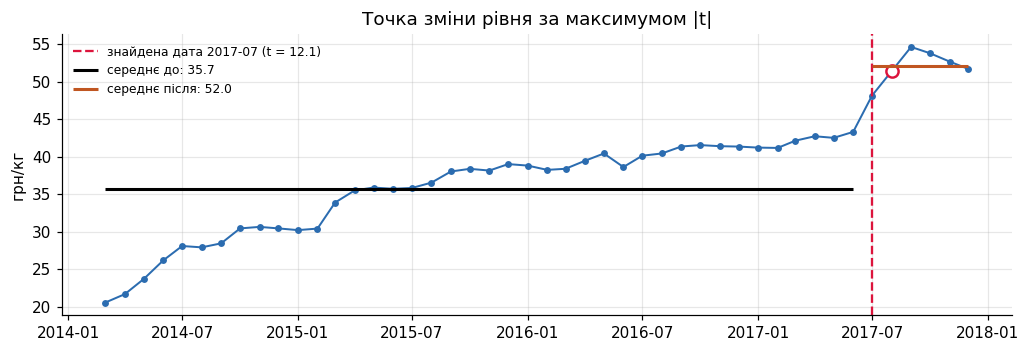

In [21]:
from scipy import stats

def scan(series, min_seg=6):
    out = []
    for k in range(min_seg, len(series) - min_seg + 1):
        a, b = series[:k], series[k:]
        t = (b.mean() - a.mean()) / np.sqrt(a.var(ddof=1) / len(a) + b.var(ddof=1) / len(b))
        out.append((k, t, a.mean(), b.mean()))
    return pd.DataFrame(out, columns=['k', 't', 'mean_before', 'mean_after'])

MIN_SEG = 6              
sc = scan(y, MIN_SEG)
top = sc.loc[sc['t'].abs().idxmax()]
k_star = int(top['k']); cp_date = dates[k_star]
a_, b_ = y[:k_star], y[k_star:]
print(f'Знайдена дата (перший місяць «нового режиму»): {cp_date:%Y-%m}')
print(f'   t-статистика = {top["t"]:.2f};  середнє до = {top["mean_before"]:.2f} ({len(a_)} міс.);  '
      f'після = {top["mean_after"]:.2f} ({len(b_)} міс.);  різниця = {top["mean_after"] - top["mean_before"]:+.2f} грн')
df_w = (a_.var(ddof=1) / len(a_) + b_.var(ddof=1) / len(b_)) ** 2 / ((a_.var(ddof=1) / len(a_)) ** 2 / (len(a_) - 1) + (b_.var(ddof=1) / len(b_)) ** 2 / (len(b_) - 1))
print(f'   «наївне» p-значення за t-розподілом Стьюдента: {2 * stats.t.sf(abs(top["t"]), df_w):.1e}')

rows = []
for m in (6, 9, 12):
    r_ = scan(y, m); j = r_['t'].abs().idxmax()
    rows.append({'мін. сегмент, міс.': m, 'дата': f'{dates[int(r_.loc[j, "k"])]:%Y-%m}', 't': round(r_.loc[j, 't'], 2)})
print('\nЧутливість до мінімальної довжини сегмента:'); print(pd.DataFrame(rows).to_string(index=False))

fig, ax = plt.subplots(figsize=(9.5, 3.3))
ax.plot(dates, y, '-o', ms=3.5, lw=1.3, color='#2b6cb0')
ax.plot(gap_date, s[gap_date], 'o', mfc='white', mec='crimson', ms=8, mew=1.6)
ax.axvline(cp_date, color='crimson', ls='--', lw=1.5, label=f'знайдена дата {cp_date:%Y-%m} (t = {top["t"]:.1f})')
ax.hlines(top['mean_before'], dates[0], dates[k_star - 1], color='k', lw=2, label=f'середнє до: {top["mean_before"]:.1f}')
ax.hlines(top['mean_after'], dates[k_star], dates[-1], color='#c05621', lw=2, label=f'середнє після: {top["mean_after"]:.1f}')
ax.set_ylabel('грн/кг'); ax.set_title('Точка зміни рівня за максимумом |t|'); ax.legend(frameon=False, fontsize=8, loc='upper left')
plt.tight_layout(); plt.show()

In [22]:
mon = cp_date.month
chg = s.diff()
print(f'1) Повторюваність: зміна ціни за перехід до місяця №{mon} ({MON[mon - 1]}) у кожному році')
tab8 = pd.DataFrame({'зміна, грн': chg[chg.index.month == mon].dropna(), 'зміна, %': pct[pct.index.month == mon].dropna()})
tab8.index = tab8.index.year
print(tab8.round(2).to_string())

amp = sm.max() - sm.min()
seas_step = sm[mon] - sm[mon - 1 if mon > 1 else 12]
print(f'\n2) Масштаб: розмах середнього сезонного профілю STL = {amp:.2f} грн; сезонний «внесок» у перехід до цього місяця = {seas_step:+.2f} грн; '
      f'фактичний стрибок {chg[cp_date]:+.2f} грн = {chg[cp_date] / amp:.1f} розмаху сезонності і {chg[cp_date] / seas_step:.1f} типового сезонного кроку')
zs = ((chg - chg.mean()) / chg.std()).drop(imp_aff).dropna().sort_values(ascending=False)
print('   z-оцінки найбільших місячних приростів (без заповнених):', ', '.join(f'{d:%Y-%m}: {v:.1f}' for d, v in zs.head(3).items()))

before6, after6 = s[:cp_date].iloc[-7:-1], s[cp_date:]
print(f'\n3) Стійкість: середнє за 6 міс. ДО = {before6.mean():.2f}; кожен місяць ПІСЛЯ ≥ {after6.min():.2f}; '
      f'мінімум після ({after6.idxmin():%Y-%m}) вищий за максимум 6 міс. до ({before6.max():.2f}) на {after6.min() - before6.max():.2f} грн')
print('   Ряд після стрибка:', ', '.join(f'{d:%Y-%m}: {v:.1f}' for d, v in s[cp_date - pd.offsets.MonthBegin(1):].items()))

1) Повторюваність: зміна ціни за перехід до місяця №7 (лип) у кожному році
      зміна, грн  зміна, %
date                      
2014        1.91      7.30
2015        0.11      0.32
2016        1.51      3.90
2017        4.84     11.17

2) Масштаб: розмах середнього сезонного профілю STL = 3.71 грн; сезонний «внесок» у перехід до цього місяця = +1.57 грн; фактичний стрибок +4.84 грн = 1.3 розмаху сезонності і 3.1 типового сезонного кроку
   z-оцінки найбільших місячних приростів (без заповнених): 2017-07: 3.2, 2015-03: 2.1, 2014-06: 1.4

3) Стійкість: середнє за 6 міс. ДО = 42.17; кожен місяць ПІСЛЯ ≥ 48.14; мінімум після (2017-07) вищий за максимум 6 міс. до (43.30) на 4.84 грн
   Ряд після стрибка: 2017-06: 43.3, 2017-07: 48.1, 2017-08: 51.4, 2017-09: 54.6, 2017-10: 53.8, 2017-11: 52.7, 2017-12: 51.7


>**Висновок до завдання 8:**
>
>**1–2. Знайдена точка.** Скануванням (по всіх датах із мінімум 6 місяцями з кожного боку) найбільша |t| — на даті **липень 2017**: **t = 12,10**, середнє до = **35,73** грн (40 міс.), після = **52,03** грн (6 міс.), різниця +16,30 грн. Безпосередньо: ціна зросла з 43,30 (червень) до 48,14 (липень), +4,84 грн, +11,2 %.
>
>**3. Чи значуща ця точка — ні.** «Наївне» p-значення за розподілом Стьюдента ≈ 2·10⁻¹⁰, але воно некоректне: ряд має тренд (будь-яка дата в трендовому ряді дає велику t), спостереження автокорельовані, а тут ще й максимум із 35 кандидатів. При мінімальному сегменті 9 або 12 місяців знайдена дата стрибає на **березень 2015** (t = 10,1), а липень 2017 стоїть на самому краю допустимого діапазону (після нього лише 6 точок, одна з яких заповнена). 
>
>**Статистично значущої точки зміни рівня за цим критерієм не знайдено.** Це не означає, що нічого не сталося: приріст липня 2017 — найбільший у ряді (**3,2σ** від середнього приросту; другий — березень 2015, 2,1σ), тож це кандидат на зсув рівня, але 46 спостережень і тренд не дозволяють його довести.
>
>**4. Зсув рівня чи сезонний сплеск.**
>* **Повторюваність.** Перехід до липня в різні роки: 2014 — +1,91 грн (+7,3 %), 2015 — +0,11 (+0,3 %), 2016 — +1,51 (+3,9 %), 2017 — **+4,84 (+11,2 %)**. Щорічного однакового сплеску немає. Типовий сезонний крок STL до липня +1,57 грн, а фактичний стрибок у 3,1 раза більший, і в 1,3 раза перевищує весь розмах середнього сезонного профілю (3,71 грн).
>* **Стійкість.** Сезонний сплеск вертається в межах року. Тут рівень після липня не повернувся до докрайового: усі місяці після ≥ 48,14, тобто вищі за максимум попередніх шести місяців (43,30), у грудні 51,67 (+8,4 грн до червня). Але після піку у вересні (54,60) ціна знизилась до 51,67 — часткова корекція, і шести місяців замало, щоб відрізнити стійкий зсув від затяжного сплеску.

## Завдання 9. Рецензія на чужий аналіз

Відкрийте `ЛР4_помилковий_аналіз.ipynb`. Це звіт, зроблений на іншому ряді з того самого набору.
Він виконується без помилок і виглядає переконливо, але містить **методологічні помилки**.

**У звіті наведіть:**
1. перелік знайдених помилок — для кожної вкажіть номер клітинки, суть помилки й **чим вона небезпечна**;
2. для трьох найсерйозніших — як саме їх виправити.

> 💡 **Підказка.** Помилок щонайменше вісім. Шукайте не синтаксис, а порушення принципів роботи з часовими рядами.

**Висновок до завдання 9:**
**1. Перелік помилок** 

| № | Клітинка | Суть помилки | Чим небезпечна |
|---|---|---|---|
| 1 | розд. 1 | «Пропусків немає» перевірено через `isna()` на ряді, який **не приведено до повної сітки**: змінна `grid` створена, але не використана. У ряді 45 місяців із 46, бракує серпня 2017. | Пропущений місяць невидимий для `isna()`, а подальші методи (STL з `period=12`, `shift(12)`, лаги ARIMA) вважають 45 точок безперервними: після пропуску все зсувається на місяць. |
| 2 | розд. 2 | Масштаб подорожчання оцінено за двома крайніми точками: ×2,47 (7,16 → 17,67). | Кінцеві точки приховують шлях: пік **36,93 у липні 2016**, після нього ціна впала на **52 %**. |
| 3 | розд. 3 | Передбачуваність двох товарів порівняно за **абсолютним** MAE в гривнях (1,38 проти 1,51) і зроблено висновок «яловичина прогнозується гірше». | Ціна яловичини в 3,7 раза вища (78,5 проти 21,3 грн). У відносних одиницях висновок **протилежний**: MAPE наївного прогнозу 7,13 % для гречки й 1,98 % для яловичини. Метрики в різних одиницях не порівнюють. |
| 4 | розд. 4 | Кореляція **рівнів** двох трендових рядів (r = 0,996) подана як доказ, що «ціни у Львівській області визначають ціни у Вінницькій». | Два ряди з трендом майже завжди сильно корелюють; кореляція не говорить про причину й напрямок. |
| 5 | розд. 5 | «STL виділив сезонну складову, отже ряд сезонний». | STL повертає сезонну складову завжди. Сила сезонності **F_S = 0,157** при порозі 0,64 (F_T = 0,813): сезонності, по суті, немає. |
| **6** | розд. 6 | ADF дав p = 0,233 > 0,05, тобто нульову гіпотезу (одиничний корінь) **не відхилено**, але зроблено висновок «ряд стаціонарний». Далі «для надійності» взято другу різницю без перевірки першої, KPSS не застосовано. | Напрямок тесту перевернуто: насправді ряд нестаціонарний. |
| 7 | розд. 7 | У тексті «два стандартні відхилення», у коді поріг **1,3σ**. Позначено 12 «аномалій» із 45 місяців. | За обіцяним порогом 2σ аномалій **немає зовсім**. Півтора десятка «аномалій» на 27 % ряду — це не аномалії. Крім того, z-оцінка від загального середнього на трендовому ряді позначає просто **початок ряду** (03–11.2014, низькі ціни) і пік 2016 року (06–08.2016), тобто фіксує рівень, а не події. |
| **8** | розд. 8 | Випадковий поділ 75/25 (`train_test_split` з перемішуванням) для часового ряду. ARIMA навчено на 33 точках, узятих з усього ряду й складених підряд, і з них зроблено прогноз на 12 кроків, який порівнюється з тестовими точками, розкиданими по позиціях 3…43. | Порушено порядок часу: навчальні точки лежать і після тестових (витік майбутнього), а «горизонт» прогнозу не відповідає жодній реальній задачі. |
| **9** | розд. 8 | MAE = 8,73 грн названо «високою точністю» і «прийнятним результатом для практичного застосування». | Це 41 % середньої ціни (21,3 грн). Без базису оцінка нічого не означає. |
| 10 | розд. 8 | Єдине порівняння — із **сезонним наївним** (9,22 грн), порахованим по всьому ряду, тобто на іншій вибірці, ніж 8,73. Наївного базису й дрейфу немає. | Порівнювати можна лише на тих самих тестових точках. |
| 11 | розд. 9 | Прогноз на 12 місяців порядком (2,2,1), який нічим не обґрунтований і не збігається ні з d з розд. 6, ні з (1,1,1) із розд. 8. Висновок: «ціна продовжить зростати». | Прогноз **падає**: 17,24 → 8,95 грн (−49 %) — висновок суперечить власному результату. |
| 12 | розд. 10 | Стовпчиковий графік із **обрізаною віссю** (нижня межа ≈ 0,995 · мінімум). | Довжина стовпчика кодує значення, тож обрізання її спотворює: у червні стовпчик у ~82 раза довший за січневий при реальному відношенні цін 1,41. |
| 13 | розд. 10 | Розглянуто лише січень–червень 2016, хоча розділ називається «Динаміка за 2016 рік». | Вікно підібране вдало: поза ним ціна досягла піку 36,93 у липні, а до жовтня впала до 25,92 (−30 %). Висновок «стрімке зростання» без цього контексту вводить в оману. |

>**2. Як виправити три найсерйозніші помилки**
>
>**Перевірка моделі (№ 8–10).** Замість перемішаного поділу — ретроспективна перевірка з рухомим початком, прогноз і факт беруться парами за часом, обов'язково порівнюється з наївним базисом:

```python
rv_full = rv_s.reindex(GRID).interpolate('linear').values      # спочатку повна сітка
for k in range(7):                                             # 7 фолдів × 3 кроки
    t = len(rv_full) - 21 + 3 * k
    pred = ARIMA(rv_full[:t], order=(1, 1, 1)).fit().forecast(3)
    err  = rv_full[t:t + 3] - pred                             # пари за часом, без np.sort
```
>Результат: наївний 2,55, дрейф 2,94, **ARIMA(1,1,1) 2,77**, сезонний наївний 7,72 грн. ARIMA не краща за найпростіший базис, тож «висока точність» не підтверджується/

>**Стаціонарність (№ 6).** Читати тести за правильним напрямком: ADF — H₀ «одиничний корінь», KPSS — H₀ «стаціонарність». Для рівня: ADF p = 0,233 (не відхиляє) і KPSS p = 0,018 (відхиляє) — **обидва вказують на нестаціонарність**, d ≥ 1. Далі застосувати обидва тести до **першої** різниці й лише тоді вирішувати: Δ¹ дає ADF p = 0,251 і KPSS p = 0,067 — тести розходяться, тому d = 2 не можна брати «для надійності», а треба порівняти d = 1 і d = 2 за якістю прогнозу на рухомому початку та за ACF різниці (лаг 2 = −0,39 у Δ² — ознака надмірного диференціювання).
>
>**Прогноз (№ 11, К10).** Порядок обирати за ACF/PACF та AICc, а не навмання; перевіряти його на рухомому початку проти наївного; будувати інтервали:

```python
trend = 'знижується' if rv_fc[-1] < rv_y[-1] else 'зростає'
print(f'Прогноз: {rv_y[-1]:.2f} → {rv_fc[-1]:.2f} грн; за моделлю ціна {trend}')
```

## Завдання 10. Експорт ряду для Orange

Збережіть підготовлений ряд у файл `ряд_для_orange.csv` **рівно у такому вигляді**:

| Стовпець | Тип | Зміст |
|---|---|---|
| `date` | текст у форматі `РРРР-ММ-ДД` | перше число місяця |
| `price` | число | ціна, пропуск уже заповнений |

Один рядок на місяць, 46 рядків плюс заголовок, роздільник — кома, кодування UTF-8.

**У звіті наведіть:**
1. підтвердження, що файл має 46 рядків даних і не містить порожніх значень.

> 💡 **Підказка.** Формат заданий жорстко: Orange має отримати **точно ті самі** дані, що й Python, інакше порівняння в Частині 2 втрачає сенс.

In [23]:
import re

OUT = 'ряд_для_orange.csv'
export = pd.DataFrame({'date': s.index.strftime('%Y-%m-%d'), 'price': s.values})
export.to_csv(OUT, index=False, sep=',', encoding='utf-8')

with open(OUT, encoding='utf-8') as f:
    lines = f.read().splitlines()
chk = pd.read_csv(OUT, encoding='utf-8', float_precision='round_trip')

print('Заголовок:', lines[0])
print('Рядків даних у файлі:', len(lines) - 1)
print('Порожніх значень:', int(chk.isna().sum().sum()))
print('Усі дати у форматі РРРР-ММ-ДД, перше число місяця:',
      all(re.fullmatch(r'\d{4}-\d{2}-01', d) for d in chk['date']))
print('Перший і останній рядки:', lines[1], '|', lines[-1])
print('Дати без пропусків (крок — 1 місяць):',
      bool((pd.to_datetime(chk['date']).diff().dropna().dt.days.between(28, 31)).all()))
print('Значення збігаються з рядом s у Python до останнього знака:',
      bool(np.array_equal(chk['price'].values, s.values)))
print(f'Заповнений пропуск {gap_date:%Y-%m}: {chk.loc[chk["date"] == gap_date.strftime("%Y-%m-%d"), "price"].iloc[0]:.4f} грн/кг')

assert len(chk) == 46 and chk['price'].notna().all() and list(chk.columns) == ['date', 'price']

Заголовок: date,price
Рядків даних у файлі: 46
Порожніх значень: 0
Усі дати у форматі РРРР-ММ-ДД, перше число місяця: True
Перший і останній рядки: 2014-03-01,20.6067 | 2017-12-01,51.6667
Дати без пропусків (крок — 1 місяць): True
Значення збігаються з рядом s у Python до останнього знака: True
Заповнений пропуск 2017-08: 51.3667 грн/кг


>**Висновок до завдання 10:**
>
>Ряд збережено у файл **`ряд_для_orange.csv`** у вказаному форматі: два стовпці `date` (текст `РРРР-ММ-ДД`, перше число місяця) та `price` (число), роздільник — кома, кодування UTF-8, без індексу.

---
# ЧАСТИНА 2. Той самий аналіз засобами Orange

*Виконується самостійно.*

Потрібен додаток **Timeseries**: у Orange відкрийте *Options → Add-ons…* і встановіть `Orange3-Timeseries`.

**Головна умова цієї частини:** Orange має отримати **ті самі дані** й **ті самі налаштування перевірки**,
що й Python у Частині 1. Тоді будь-яка розбіжність у числах пояснюється **лише означеннями метрик**,
а не різними даними чи різними моделями. Саме це вам і треба довести.

## Завдання 11. Потік опрацювання даних

Побудуйте в Orange потік:

`File` → `As Timeseries` → `Interpolate` → `Line Chart`

У віджеті **File** завантажте свій `ряд_для_orange.csv`; переконайтеся, що `date` розпізнано
як **time**, а `price` — як **numeric**. У віджеті **As Timeseries** оберіть `date` як часову змінну.

**У звіті наведіть:**
1. знімок екрана з побудованим потоком;
2. знімок `Line Chart` із вашим рядом;
3. підтвердження, що графік у Orange збігається з графіком із завдання 3.

> 💡 **Підказка.** Якщо `date` розпізнано як текст, поверніться до завдання 10 і перевірте формат дати.

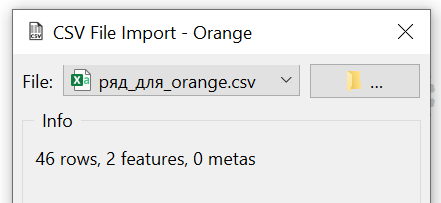

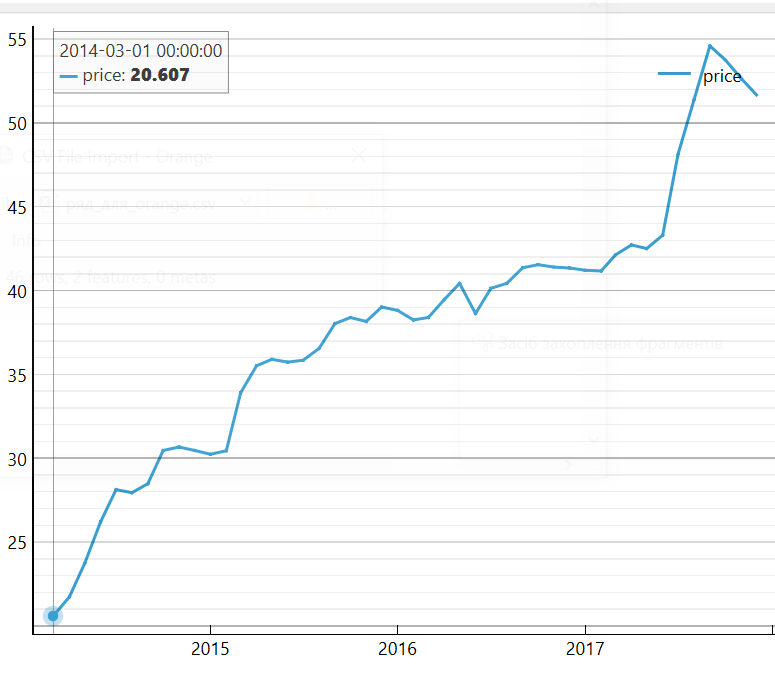

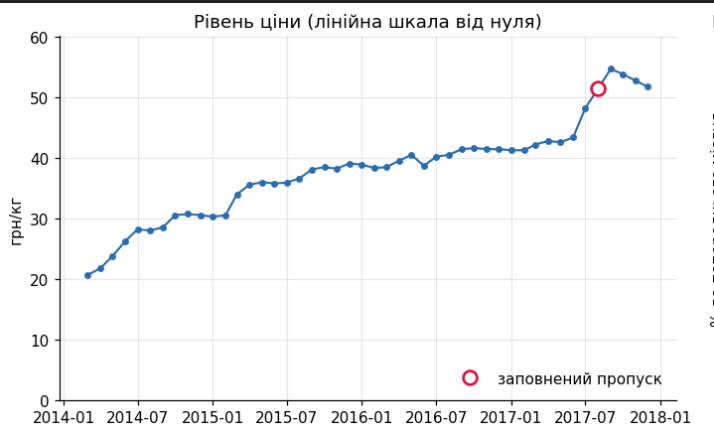

>**Висновок до завдання 11:**
>
>Графіки збігаються.

## Завдання 12. Автокореляція та диференціювання

Додайте до потоку віджети `Correlogram`, `Difference` та `Seasonal Adjustment`.

**У звіті наведіть:**
1. знімок корелограми;
2. зіставлення з ACF із завдання 5: **чи збігаються висновки** про значущі лаги;
3. знімок сезонно скоригованого ряду та порівняння з сезонною складовою STL із завдання 4.

> 💡 **Підказка.** Orange і statsmodels рахують автокореляцію однаково — якщо картина різна, перевірте, чи однакові дані на вході.

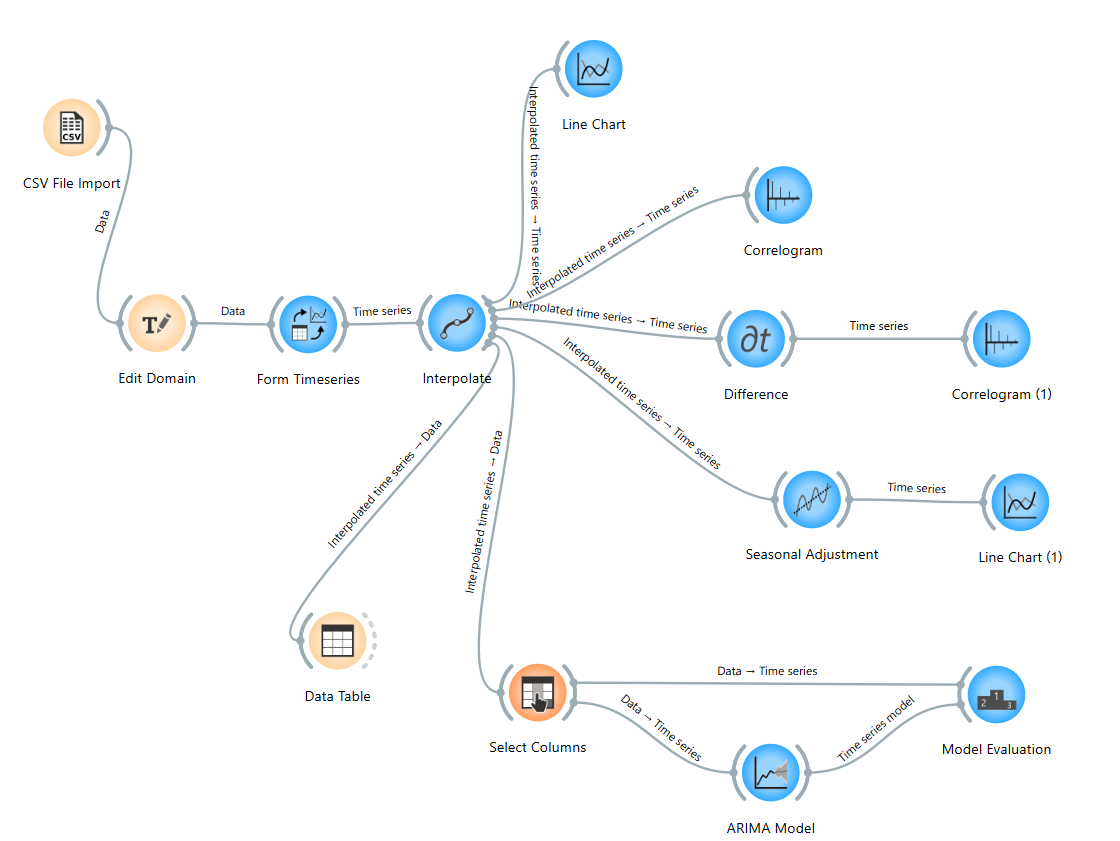

**Зіставлення корелограми з Orange з графіком ACF**

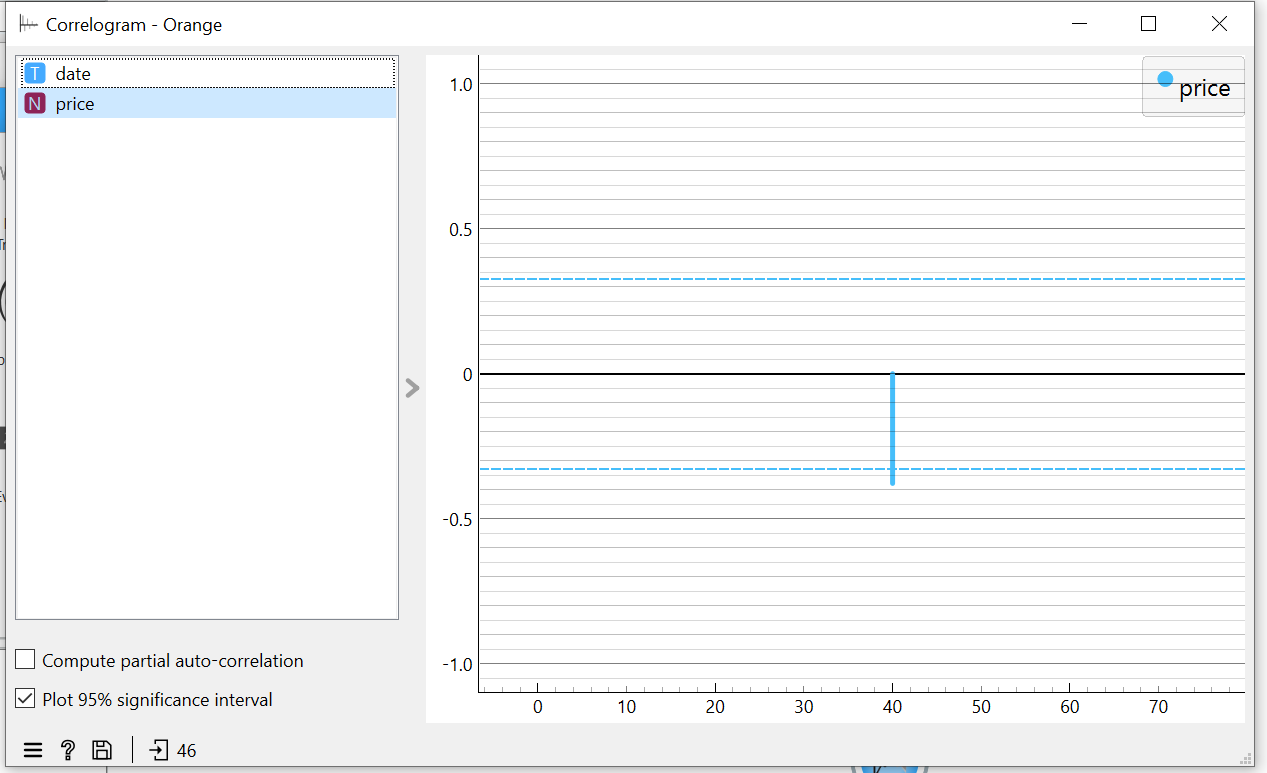

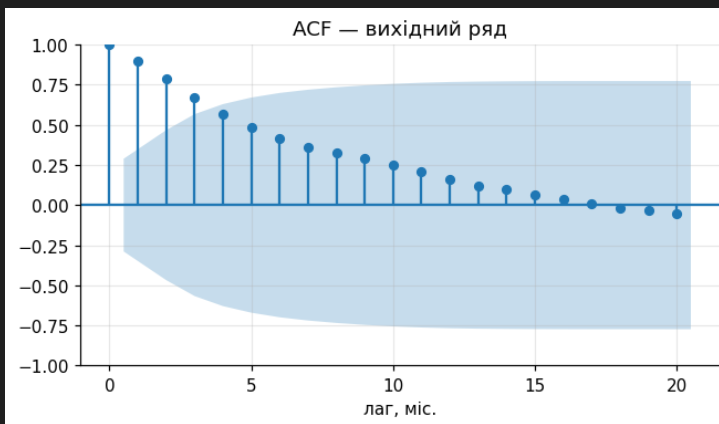

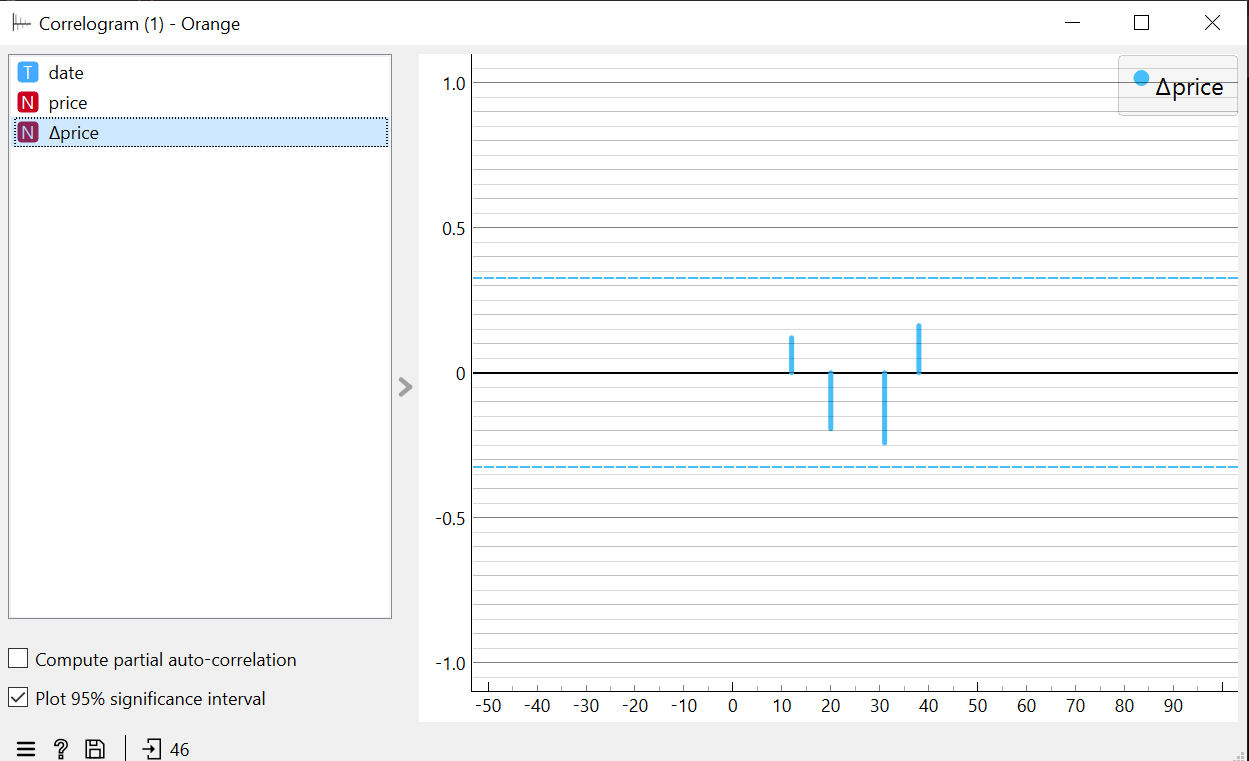

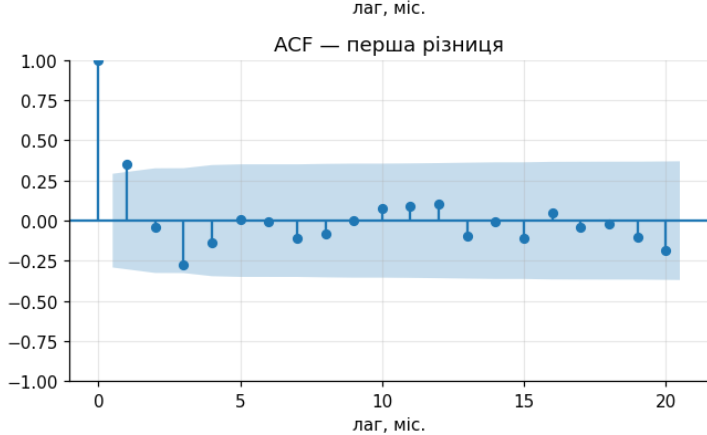

**Сезонно скоригований ряд та сезонно складова STL**

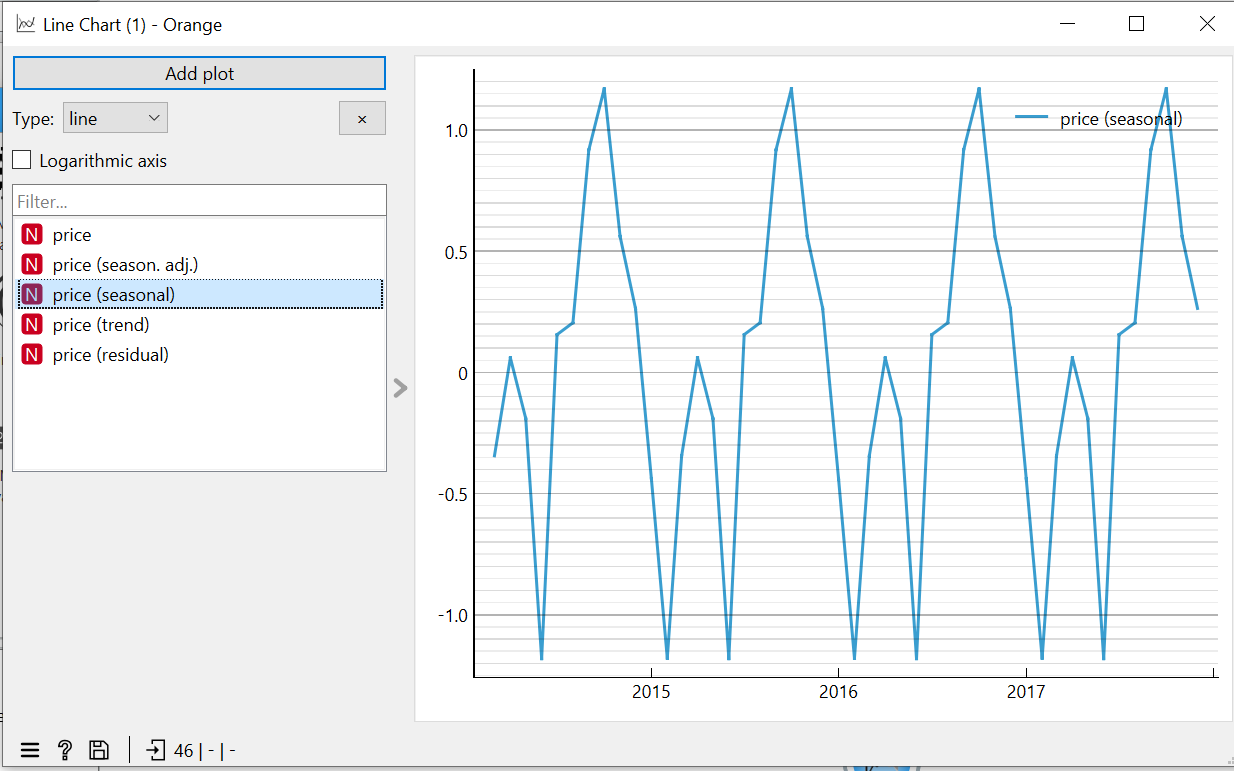

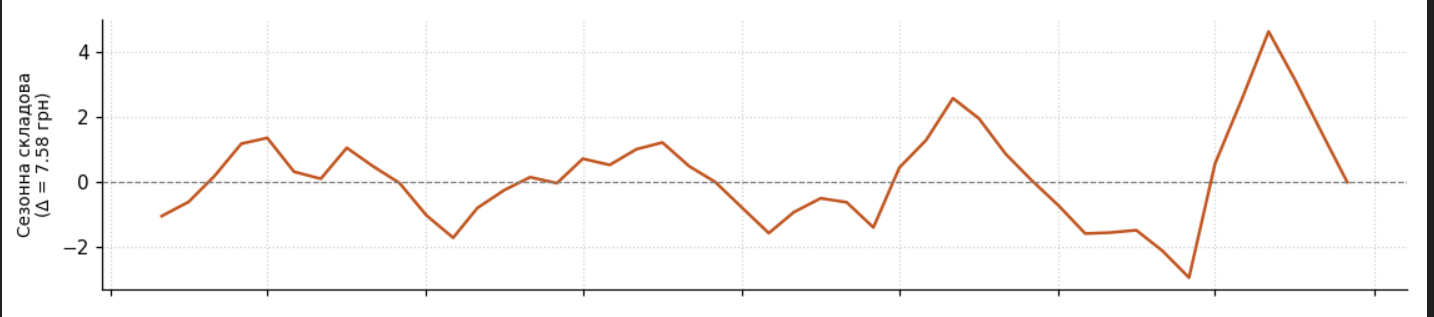

>**Висновок до завдання 12:**
>
>Сезонні графіки у нас вийшли абсолютно різними, і це через те, що в Orange використовується інший метод.
>
>**Orange (класичне розкладання)** рахує для кожного місяця одне середнє відхилення від тренду за всі роки і повторює його щороку - таким чином на графіку однакові стрибки.
>
>**STL** в кожному році показує різну сезонність - він групує відхилення від тренду за місяцями і проводить через них не одне середнє, а плавну криву, що найбільше враховує сусідні роки.

## Завдання 13. Модель і оцінювання

Додайте `ARIMA Model` з порядком **(1, 1, 1)** та `Model Evaluation`.

У віджеті **Model Evaluation** встановіть **Number of folds = 7** та **Forecast steps = 3**.

**У звіті наведіть:**
1. знімок таблиці Model Evaluation з усіма метриками;
2. **що станеться, якщо лишити типові налаштування** (20 фолдів × 3 кроки) — наведіть повідомлення, яке видасть Orange, і поясніть, звідки воно береться;
3. які саме 7 фолдів перевіряє Orange — тобто на яких відрізках ряду навчається модель.

> 💡 **Підказка.** Orange відмовиться працювати при типових налаштуваннях. Це не збій, а наслідок довжини вашого ряду — порахуйте, якої саме.

**Таблиця Model Evaluation (7 фолдів x 3 роки)**

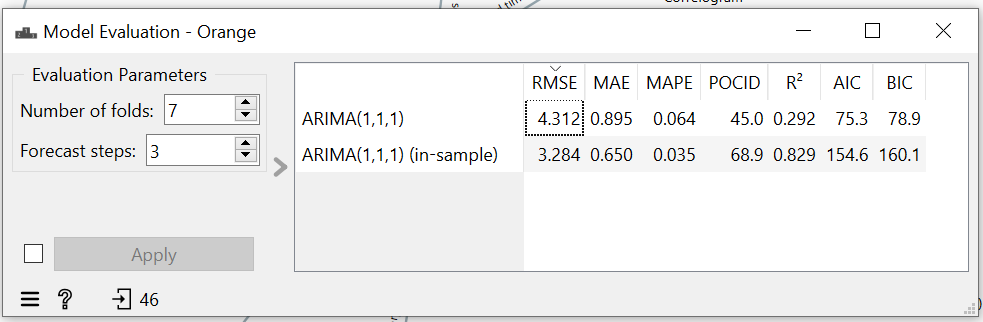

**Таблиця Model Evaluation (20 фолдів x 3 роки)**

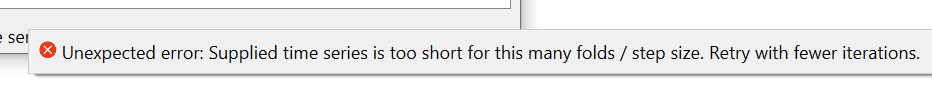

>**Висновок до завдання 13:**
>
>Модель в Orange навчалась на тих самий відрізках часу, що і власна реалізація на Python, так як RMSE однаковий.
>
>| Модель | RMSE |
>|---|---|
>| ARIMA(1,1,1) (Orange) | 4.312 |
>| ARIMA(1,1,1) (Python) | 4.312 |

## Завдання 14. Чому числа не збігаються

Порівняйте метрики Orange з метриками, які ви отримали в Частині 1 для **тієї самої** моделі
ARIMA(1,1,1) на **тих самих** 7 фолдах.

Для кожної з чотирьох метрик Orange — `RMSE`, `MAE`, `MAPE`, `POCID` — **відтворіть її значення в Python**,
тобто напишіть формулу, за якою Orange отримав саме це число, і переконайтеся, що ваш розрахунок
збігається з таблицею Orange до третього знака.

**У звіті наведіть:**
1. таблицю на чотири рядки: метрика · значення Orange · ваше відтворення в Python · формула;
2. **яка з метрик не відповідає своїй назві** — і чим саме вона відрізняється від того, що зазвичай позначають цією абревіатурою;
3. яка метрика збіглася між середовищами одразу і чому;
4. висновок: що саме треба перевіряти, перш ніж порівнювати числа з двох різних інструментів.

> 💡 **Підказка.** Жодна з розбіжностей не є помилкою Orange. Усі формули відкриті — шукайте їх у вихідному коді додатка Timeseries, файл `functions.py`.

In [26]:
ORANGE_OUT = {'RMSE': 4.312, 'MAE': 0.895, 'MAPE': 0.064, 'POCID': 45.0}  
ORANGE_IN  = {'RMSE': 3.284, 'MAE': 0.650, 'MAPE': 0.035, 'POCID': 68.9}  
TOL = {'RMSE': 6e-4, 'MAE': 6e-4, 'MAPE': 6e-4, 'POCID': 0.06}   

y_out = df_ar['actual'].to_numpy(float); p_out = df_ar['pred'].to_numpy(float)  
y_in  = s.values.astype(float);          p_in  = y_in - np.asarray(fit_full.resid, float)  

FORMULAS = {
    'RMSE': {
        'sqrt( mean(e^2) )':                         lambda y, p: np.sqrt(np.mean((y - p) ** 2)),
    },
    'MAE': {
        'mean(|e|)  — середнє':                      lambda y, p: np.mean(np.abs(y - p)),
        'median(|e|)  — медіана':                    lambda y, p: np.median(np.abs(y - p)),
        '|mean(e)|  — модуль середнього':            lambda y, p: abs(np.mean(y - p)),
    },
    'MAPE': {
        '100 * mean(|e| / y)  — класична, %':        lambda y, p: 100 * np.mean(np.abs(y - p) / np.abs(y)),
        'mean(|e| / y)  — класична, частка':         lambda y, p: np.mean(np.abs(y - p) / np.abs(y)),
        'sum(|e|) / sum(|y|)  — частка':             lambda y, p: np.sum(np.abs(y - p)) / np.sum(np.abs(y)),
        'mean(|e| / yhat)  — ділення на прогноз':    lambda y, p: np.mean(np.abs(y - p) / np.abs(p)),
    },
    'POCID': {
        '100 * mean[ dy * dyhat > 0 ] ':
            lambda y, p: 100 * np.mean(np.diff(y) * np.diff(p) > 0),
    },
}

rows, chosen = [], {}
for metric, cands in FORMULAS.items():
    for name, f in cands.items():
        vo, vi = f(y_out, p_out), f(y_in, p_in)
        ok_o = abs(vo - ORANGE_OUT[metric]) <= TOL[metric]
        ok_i = abs(vi - ORANGE_IN[metric])  <= TOL[metric]
        rows.append({'метрика': metric, 'формула': name, 'out-of-sample': vo, 'Orange (out)': ORANGE_OUT[metric],
                     'in-sample': vi, 'Orange (in)': ORANGE_IN[metric], 'збіг': '✔✔' if ok_o and ok_i else ('✔' if ok_o else '')})
        if ok_o and ok_i and metric not in chosen:
            chosen[metric] = (name, vo, vi)
diag = pd.DataFrame(rows)
print('Усі перевірені формули (збіг ✔✔ = збіглися і для рядка out-of-sample, і для in-sample в Orange):')
print(diag.to_string(index=False, float_format=lambda v: f'{v:.4f}'))

pocid_fold = np.mean([100 * np.mean(np.diff(g['actual'].values) * np.diff(g['pred'].values) > 0)
                      for _, g in df_ar.groupby('fold')])
print(f'\nПеревірка гіпотези «POCID по фолдах окремо»: {pocid_fold:.1f}  (Orange: {ORANGE_OUT["POCID"]})')

missing = [m for m in FORMULAS if m not in chosen]
assert not missing, f'Жодна з формул не збіглася з Orange для: {missing} — перегляньте таблицю вище'

final = pd.DataFrame({
    'метрика': list(chosen),
    'Orange': [ORANGE_OUT[m] for m in chosen],
    'відтворення в Python': [chosen[m][1] for m in chosen],
    'формула': [chosen[m][0] for m in chosen],
}).set_index('метрика')
print('\nПідсумкова таблиця:')
print(final.to_string(float_format=lambda v: f'{v:.3f}'))

Усі перевірені формули (збіг ✔✔ = збіглися і для рядка out-of-sample, і для in-sample в Orange):
метрика                                формула  out-of-sample  Orange (out)  in-sample  Orange (in) збіг
   RMSE                      sqrt( mean(e^2) )         4.3116        4.3120     3.2842       3.2840   ✔✔
    MAE                   mean(|e|)  — середнє         2.8246        0.8950     1.3182       0.6500     
    MAE                 median(|e|)  — медіана         0.8950        0.8950     0.6502       0.6500   ✔✔
    MAE         |mean(e)|  — модуль середнього         0.7770        0.8950     0.7895       0.6500     
   MAPE     100 * mean(|e| / y)  — класична, %         5.8275        0.0640     4.5311       0.0350     
   MAPE      mean(|e| / y)  — класична, частка         0.0583        0.0640     0.0453       0.0350     
   MAPE          sum(|e|) / sum(|y|)  — частка         0.0638        0.0640     0.0348       0.0350   ✔✔
   MAPE mean(|e| / yhat)  — ділення на прогноз         0.0613  

>**Висновок до завдання 14:**
>
>Дані й модель в обох середовищах однакові (RMSE збігся до третього знака), тому всі розбіжності нижче — це **різні означення метрик**, а не різні прогнози.
>
>**1. Таблиця**
>
>| Метрика | Orange | Python (відтворення) | Формула в Orange (e = y − ŷ, n = 21 прогноз) | «Звичайне» значення з Частини 1 |
>|---|---|---|---|---|
>| RMSE | 4,312 | 4,312 | √( (1/n)·Σ eₜ² ) | 4,312 грн |
>| MAE | 0,895 | 0,895 | **медіана** | 2,825 грн  |
>| MAPE | 0,064 | 0,064 | Σ eₜ / Σ yₜ, у **частках** | 5,83 % (= 0,058) |
>| POCID | 45,0 | 45,0 | 100 · (1/(n−1)) · Σ [ (yₜ − yₜ₋₁)(ŷₜ − ŷₜ₋₁) > 0 ] = 9/20 | — |
>
>**2. Яка метрика не відповідає назві.** Найпоказовіше — **MAE**. Абревіатура означає *mean* absolute error, тобто **середнє** модулів помилок (у моєму завданні 7 — 2,825 грн). Orange ж видає число 0,895 — це **медіана** модулів помилок: вона нечутлива до кількох великих промахів, тому втричі менша за середнє. 
>Аналогічно **MAPE** у Orange — не «середнє від відсоткових помилок» |eₜ/yₜ| у відсотках (моє 5,83 %), а **сумарна** абсолютна помилка, поділена на суму фактичних значень (зважена версія, WAPE) і подана **часткою**, а не відсотком: 0,064 ≠ 0,0583 навіть після переведення з відсотків у частки. Тому при порівнянні «0,064» і «5,83 %» треба брати до уваги і одиниці, і знаменник.
>**POCID** у Orange є стандартною формулою (частка збігів знаку зміни факту й прогнозу), але рахується по **склеєній** послідовності з 21 прогнозу: 20 різниць, з яких частина перетинає межі фолдів і порівнює прогнози, зроблені з різних початків.
>
>**3. Що збіглося одразу — RMSE.** У нього немає «варіантів прочитання»: корінь із середнього квадрата помилки по всіх 21 прогнозу, без нормування, відсотків чи медіан. Обидва інструменти беруть однакові дані, ті самі 7 фолдів × 3 кроки й однакові параметри моделі, тому й число однакове (4,312).
>
>**4. Що перевіряти, перш ніж порівнювати числа з двох інструментів.** 
>* Що **дані й розбиття** однакові (ряд, заповнений пропуск, кількість фолдів і кроків); 
>* що **модель** однакова (порядок, наявність константи/дрейфу); 
>* що **означає назва метрики** в кожному інструменті: середнє чи медіана, звичайне чи зважене, відсотки чи частки, у яких одиницях; 
>* як **агрегується по фолдах**: усі помилки разом чи метрика на кожному фолді з наступним усередненням. Єдиний надійний спосіб — відтворити число власною формулою.

## Завдання 15. Матриця напрямку зміни

Метрика `POCID` у Orange вимірює, чи правильно модель передбачає **напрямок** зміни ціни.
Розгорніть її в таблицю 2×2: рядки — що сталося насправді (зросла / впала),
стовпці — що передбачила модель.

**У звіті наведіть:**
1. заповнену матрицю 2×2 для вашої моделі;
2. перевірку, що частка правильних передбачень збігається зі значенням POCID із Orange;
3. висновок: чи корисна ваша модель для рішення «купувати зараз чи чекати», і чому це **інше питання**, ніж те, на яке відповідають MAE та RMSE.

> 💡 **Підказка.** Ця матриця — часоворядовий відповідник матриці похибок із класифікації.

Пар для POCID: 20;  нульових змін факту: 0,  прогнозу: 0

1) Матриця 2×2 (рядки — що сталося, стовпці — що передбачила модель):
                    зросла  впала
факт ↓ / прогноз →               
зросла                   7      4
впала                    7      2
   правильно: 9 із 20  →  45.0 %

2) POCID з Orange = 45.0;  частка правильних із матриці = 45.0;  збіг: True


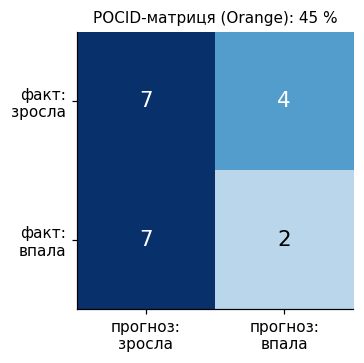

In [32]:
from scipy.stats import binomtest

d15 = df_ar.sort_values('date').reset_index(drop=True)         
y15, p15 = d15['actual'].to_numpy(float), d15['pred'].to_numpy(float)
dy, dp = np.diff(y15), np.diff(p15)                             
print(f'Пар для POCID: {len(dy)};  нульових змін факту: {int((dy == 0).sum())},  прогнозу: {int((dp == 0).sum())}')

LAB = ['зросла', 'впала']
def confusion(act_up, pred_up):
    m = pd.DataFrame(0, index=pd.Index(LAB, name='факт ↓ / прогноз →'), columns=LAB)
    for a, p in zip(act_up, pred_up):
        m.loc[LAB[0] if a else LAB[1], LAB[0] if p else LAB[1]] += 1
    return m

M1 = confusion(dy > 0, dp > 0)
TP, FN, FP, TN = M1.loc['зросла', 'зросла'], M1.loc['зросла', 'впала'], M1.loc['впала', 'зросла'], M1.loc['впала', 'впала']
acc1 = 100 * (TP + TN) / M1.values.sum()
print('\n1) Матриця 2×2 (рядки — що сталося, стовпці — що передбачила модель):')
print(M1.to_string())
print(f'   правильно: {TP + TN} із {M1.values.sum()}  →  {acc1:.1f} %')

print(f'\n2) POCID з Orange = {ORANGE_OUT["POCID"]};  частка правильних із матриці = {acc1:.1f};  '
      f'збіг: {abs(acc1 - ORANGE_OUT["POCID"]) <= TOL["POCID"]}')
assert abs(acc1 - ORANGE_OUT['POCID']) <= TOL['POCID']

n1 = M1.values.sum(); k1 = int(TP + TN)
base_up = 100 * (dy > 0).mean()
ci = binomtest(k1, n1).proportion_ci(confidence_level=0.95, method='wilson')

fig, ax = plt.subplots(figsize=(4.5, 3.4))

ax.imshow(M1.values, cmap='Blues', vmin=0)
ax.set_xticks([0, 1])
ax.set_xticklabels(['прогноз:\nзросла', 'прогноз:\nвпала'])
ax.set_yticks([0, 1])
ax.set_yticklabels(['факт:\nзросла', 'факт:\nвпала'])
ax.grid(False)

for (i, j), v in np.ndenumerate(M1.values):
    ax.text(j, i, v, ha='center', va='center', fontsize=14,
            color='white' if v > M1.values.max() / 2 else 'black')

ax.set_title(f'POCID-матриця (Orange): {acc1:.0f} %', fontsize=10)

plt.tight_layout()
plt.show()

>**Висновок до завдання 15:**
>
>**1–2. Матриця й перевірка.** Матриця 2×2 побудована з тих самих 21 прогнозу ARIMA(1,1,1): рядки — чи зросла ціна насправді (Δy > 0), стовпці — чи зросла вона за прогнозом моделі (Δŷ > 0); діагональ — правильні напрямки. Частка правильних — **9 із 20 = 45,0 %**, що збігається з POCID з Orange (45,0). Отже, POCID — це просто *точність* (accuracy) класифікатора «вгору / вниз», а матриця — часоворядовий відповідник матриці похибок: діагональ — влучання, поза діагоналлю — хибні сигнали «зросте» й пропущені зростання.
>
>**3. Чи корисна модель для рішення «купувати зараз чи чекати».** **Ні, за цією перевіркою — ні.** 
>* 45 % — це **нижче за 50 %**, тобто модель вгадує напрям не краще, ніж підкинута монета; водночас при n = 20 95-відсотковий інтервал точності (приблизно 26–66 %) охоплює і 50 %, тож і «гірша за монету» довести не можна — просто **жодної переваги не виявлено**.
>* Ряд за 46 місяців зріс у 2,5 раза, а місяців здешевлення було мало й вони невеликі. Тому тривіальне правило «завжди чекай зростання» влучало б значно частіше (його точність виведена в клітинці), і модель, яка програє навіть йому, не дає підстав довіряти її сигналу.
>* ARIMA(1,1,1) без дрейфу будує майже рівні траєкторії, знак яких визначається згасанням останнього приросту, а не трендом; до того ж у POCID сусідні прогнози на межі фолдів зроблені з різних початків, тому такий «напрямок» лише частково відповідає реальному рішенню.
>
>**Чому це інше питання, ніж у MAE та RMSE.** MAE і RMSE міряють **розмір** помилки в гривнях і не знають, у який бік вона спрямована: модель з малою MAE може весь час помилятися в знаку (коли ціна майже не змінюється, а прогноз «коливається» навколо неї), а модель із великою MAE — бути завжди права щодо напрямку, просто недооцінюючи масштаб зростання (так поводиться ARIMA без дрейфу на ряді з трендом). Рішення «купити чи чекати» залежить від **знаку** очікуваної зміни, а не від її точної величини, і матриця напрямку відповідає саме на це. 

---
# Загальний висновок

Напишіть 8–12 речень, які відповідають на такі питання:

1. Чи є у вашому ряді сезонність і чим ви це довели?
2. Який метод прогнозування виявився найкращим і чи перевершив він найпростіший базис?
3. Чи знайшли ви точку зміни режиму; якщо так — чи є для неї зовнішнє пояснення?
4. Чому однаково названі метрики у двох середовищах дали різні числа?
5. Чого ви не змогли встановити через те, що ряд має лише 46 спостережень?

>* Формально сезонність у ряді є: сила сезонності за STL F_S = 0,763 перевищує поріг 0,64. Але вона статистично недоведена: пік сезонної складової припав на стрибок 2017 року, а розмах середнього сезонного профілю (≈ 3,7 грн, близько 10 % середньої ціни) мізерний порівняно з трендом (≈ 29,5 грн, F_T = 0,989).
>* Найкращим виявився найпростіший базис, наївний прогноз: на ретроспективній перевірці (7 фолдів × 3 кроки) він має MAE 2,04 грн, RMSE 3,45 і MAPE 4,22 %.
>* ARIMA(1,1,1) його не перевершила (MAE 2,83, RMSE 4,31, MAPE 5,83 %), тож як робочий прогноз для цього ряду вона не виправдовує свою складність. Навіть із дрейфом (MAE 2,48) вона лишається гіршою за наївний прогноз.
>* Точку зміни режиму скануванням знайдено в липні 2017 року (t = 12,10, середнє 35,7 → 52,0 грн), але статистично значущою вона не є. Тренд і автокореляція роблять наївне p-значення некоректним, а при мінімальному сегменті 9–12 місяців знайдена дата переходить на березень 2015 року.
>* Однаково названі метрики дали різні числа, бо в Orange вони мають інші означення. RMSE збіглася одразу (4,312), бо означення в обох середовищах однакове. Orange «MAE» (0,895) — це медіана модулів помилок, а не середнє (у Python 2,825). Orange «MAPE» (0,064) — це Σ|e| / Σ|y| у частках, а не середній відсоток (у Python 5,83 %). POCID Orange рахує по склеєній послідовності з 21 прогнозу (9 із 20 = 45,0 %).
>* Тому висновок «метрики різні, бо середовища різні» нічого не пояснює. Порівнювати числа можна лише після відтворення формул і перевірки, що однакові дані, фолди та модель.
>* Через те, що ряд має лише 46 спостережень, я не змогла надійно встановити сезонність: кожен календарний місяць оцінено лише по 3–4 точках. Не можемо довести зсув рівня в 2017 році, бо після нього лише 6 місяців, один із яких заповнений інтерполяцією.
>* Оцінка якості прогнозів теж нестійка: усього 21 точка, а фолди 6 і 7 дають більшість помилки. Із 20 пар POCID 95 % інтервал для точності напрямку (приблизно 26–66 %) охоплює 50 %, тож ні переваги, ні програшу моделі над монетою довести не можна. 

---
# Критерії оцінювання

| Бали | Умова |
|---|---|
| **0** | Ряд не розкладено або прогноз не побудовано. Робота не зарахована. |
| **2** | Виконано лише Частину 1: ряд розкладено й прогноз побудовано, але в Orange аналіз не відтворено. |
| **3** | Виконано обидві частини, проте прогноз не зіставлено з наївним базисом, а розбіжність результатів двох середовищ не пояснено. |
| **4** | Ряд розкладено на складові; прогноз зіставлено з наївним базисом за ретроспективною перевіркою з рухомим початком; той самий аналіз відтворено в Orange; зіставлено результати двох середовищ і пояснено розбіжність метрик. |

**Знімаються бали за:**

* графіки без пояснення вибору геометрії та шкали;
* числа без письмового висновку;
* прогноз без порівняння з базисом;
* висновок «метрики різні, бо середовища різні» без відтворення формул;
* зошит, який не виконується від початку до кінця.

---
# Декларація про використання штучного інтелекту

Використання інструментів штучного інтелекту під час виконання цієї роботи **дозволено**.
Умова одна: ви маєте розуміти кожен рядок зданого коду й кожне написане твердження
і бути готовим пояснити їх на захисті.

Заповніть таблицю. Якщо ШІ не використовувався, напишіть «не використовувався» в першому рядку
й залиште решту порожньою.

| Питання | Ваша відповідь |
|---|---|
| Які інструменти використано (назва, версія) | Gemini 3.8 flash |
| Для яких саме завдань | завдання 2-15 |
| Що саме було згенеровано (код / текст / пояснення / виправлення помилок) | код |
| Що ви змінили у згенерованому результаті й чому | деякі графіки були не інформативні, пояснення до результатів не мали обгрунтування |
| Що з отриманого ви **перевірили самостійно** і яким способом | формули із завдання з заповненням пропуску, а також завдання 5, 6, 7 - що це за метрики, як і для чого вони використовуються і що говорять про наші дані |
| Чи траплялися у відповідях ШІ помилки; якщо так — які | в числах ні, так то ШІ міг робити помилкові висновки, просто придумуючи причини, а також погано пояснював, як працювати із Orange (там, на жаль, траплялись помилки, які блокували отримання результату) |

**Підтверджую, що розумію весь зданий код і всі зроблені висновки
та можу пояснити будь-яку їх частину на захисті роботи.**

Підпис: Щербан Ярина  Дата: 29.10.26